In [1]:
from pyproj import Transformer 

trans_utm = Transformer.trans_utm()


In [7]:
import numpy as np
x1 = [1,2,3,4]

var = np.var(x1)
print(var)

1.25


What is wrong
python
if any(text in col for text in skip_names):
This is checking the wrong direction. col is a list, so text in col asks whether the full string text is an element of the list, not whether it appears inside each column name.
You want to check whether a skip word appears inside the current column name

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

# Set style for better visualizations
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except:
    plt.style.use('seaborn-whitegrid')
sns.set_palette("husl")

class mouf:
    """
    Geochemical Data Analyzer (mouf)
    
    A comprehensive class for cleaning, analyzing, and modeling geochemical data.
    
    Features:
    - Data cleaning and conversion to numeric
    - Missing value handling (drop or impute)
    - Exploratory Data Analysis (EDA)
    - Outlier detection and handling (IQR method)
    - Pearson correlation analysis
    - Linear regression modeling
    - Visualization and reporting
    """
    
    def __init__(self, df):
        """
        Initialize the mouf class with geochemical data.
        
        Parameters:
        -----------
        df : pandas DataFrame
            The geochemical data to analyze
        """
        self.df = df.copy()
        self.original_df = df.copy()
        self.models = {}
        self.results = {}
        self.report = {}
        self.feature_n = None
        self.target_n = None
        
        # Define columns to skip during conversion
        self.skip_col = ['Sample_ID', 'Sample', 'ID', 'Lithology', 'Rock_Type']
        self.numeric_col = []
        self.outlier_report = {}
        
        print("🔬 mouf initialized successfully")
        print(f"   Samples: {len(self.df)}")
        print(f"   Columns: {len(self.df.columns)}")
        print(f"   Column names: {list(self.df.columns)}")
        print("-" * 60)
    
    # ============================================
    # 1. DATA CLEANING
    # ============================================
    
    def remove_first(self, first=True):
        """
        Remove the first row from the DataFrame.
        """
        if first:
            self.df = self.df.iloc[1:].copy()
            self.report['remove_first'] = True
            print("✅ First row removed")
        else:
            self.report['remove_first'] = False
            print("⏭️ Kept first row")
        
        self.df = self.df.reset_index(drop=True)
        return self.df
    
    def conv_numeri(self):
        """
        Convert all columns to numeric, skipping non-numeric columns.
        """
        print("\n🔄 CONVERTING COLUMNS TO NUMERIC")
        print("-" * 50)
        
        converted_count = 0
        skipped_cols = []
        failed_cols = []
        
        for col in self.df.columns:
            if any(skip in col for skip in self.skip_col):
                skipped_cols.append(col)
                print(f"   ⏭️ Skipping: {col}")
                continue
            
            try:
                converted_col = pd.to_numeric(self.df[col], errors='coerce')
                
                if converted_col.notna().any():
                    self.df[col] = converted_col
                    self.numeric_col.append(col)
                    converted_count += 1
                    print(f"   ✅ Converted: {col}")
                else:
                    failed_cols.append(col)
                    print(f"   ⚠️ Could not convert: {col} (all values are NaN)")
                    
            except Exception as e:
                failed_cols.append(col)
                print(f"   ❌ Error converting {col}: {e}")
                pass
        
        self.report['conv_numeri'] = converted_count
        self.report['skipped_cols'] = skipped_cols
        self.report['failed_cols'] = failed_cols
        
        print(f"\n✅ Converted {converted_count} columns to numeric")
        print(f"   Numeric columns: {self.numeric_col}")
        
        return self.df
    
    # ============================================
    # 2. MISSING VALUE HANDLING
    # ============================================
    
    def handle_missing_values(self, strategy='drop', columns=None):
        """
        Handle missing values in the dataset.
        
        Parameters:
        -----------
        strategy : str, default='drop'
            'drop' - Remove rows with NaN
            'mean' - Replace with column mean
            'median' - Replace with column median
            'zero' - Replace with 0
        columns : list, optional
            List of columns to check. If None, uses all numeric columns.
        """
        print("\n🔧 HANDLING MISSING VALUES")
        print("-" * 50)
        
        if columns is None:
            columns = self.numeric_col
        
        # Check for missing values
        missing_counts = self.df[columns].isna().sum()
        total_missing = missing_counts.sum()
        
        if total_missing == 0:
            print("✅ No missing values found!")
            return self.df
        
        print(f"⚠️ Found {total_missing} missing values")
        print(missing_counts[missing_counts > 0])
        
        if strategy == 'drop':
            before = len(self.df)
            self.df = self.df.dropna(subset=columns)
            after = len(self.df)
            print(f"✅ Dropped {before - after} rows with missing values")
            
        elif strategy in ['mean', 'median']:
            imputer = SimpleImputer(strategy=strategy)
            self.df[columns] = imputer.fit_transform(self.df[columns])
            print(f"✅ Imputed missing values using '{strategy}' strategy")
            
        elif strategy == 'zero':
            self.df[columns] = self.df[columns].fillna(0)
            print("✅ Replaced missing values with 0")
            
        else:
            raise ValueError(f"Unknown strategy: {strategy}")
        
        self.report['missing_values_handled'] = strategy
        return self.df
    
    # ============================================
    # 3. SET FEATURES AND TARGET
    # ============================================
    
    def set_features_target(self, feature_cols, target_col):
        """
        Set which columns are features (X) and which is target (y).
        """
        # Check if columns exist
        missing_features = [c for c in feature_cols if c not in self.df.columns]
        if missing_features:
            raise ValueError(f"Feature columns not found: {missing_features}")
        
        if target_col not in self.df.columns:
            raise ValueError(f"Target column not found: {target_col}")
        
        self.feature_n = feature_cols
        self.target_n = target_col
        self.X = self.df[feature_cols]
        self.y = self.df[target_col]
        
        self.report['features'] = feature_cols
        self.report['target'] = target_col
        
        print(f"\n✅ Features set: {feature_cols}")
        print(f"✅ Target set: {target_col}")
        print(f"   X shape: {self.X.shape}")
        print(f"   y shape: {self.y.shape}")
        
        return self.X, self.y
    
    # ============================================
    # 4. OUTLIER DETECTION AND HANDLING
    # ============================================
    
    def detect_outliers_iqr(self, multiplier=1.5):
        """
        Detect outliers using the IQR method.
        """
        print("\n🔍 OUTLIER DETECTION (IQR METHOD)")
        print("-" * 50)
        print(f"   IQR multiplier: {multiplier}")
        
        self.outlier_report = {}
        outlier_indices = set()
        
        for col in self.numeric_col:
            if col not in self.df.columns:
                continue
            
            data = self.df[col].dropna()
            
            if len(data) == 0:
                continue
            
            Q1 = data.quantile(0.25)
            Q3 = data.quantile(0.75)
            IQR = Q3 - Q1
            
            lower_bound = Q1 - multiplier * IQR
            upper_bound = Q3 + multiplier * IQR
            
            outliers = (data < lower_bound) | (data > upper_bound)
            outlier_count = outliers.sum()
            
            self.outlier_report[col] = {
                'count': outlier_count,
                'lower_bound': lower_bound,
                'upper_bound': upper_bound,
                'Q1': Q1,
                'Q3': Q3,
                'IQR': IQR
            }
            
            if outlier_count > 0:
                outlier_indices.update(data[outliers].index.tolist())
                print(f"   {col}: {outlier_count} outliers detected")
                print(f"      Bounds: [{lower_bound:.4f}, {upper_bound:.4f}]")
        
        self.report['outliers'] = self.outlier_report
        
        total_outliers = sum([v['count'] for v in self.outlier_report.values()])
        print(f"\n✅ Total outliers detected: {total_outliers}")
        
        return self.outlier_report
    
    def remove_outliers(self):
        """
        Remove rows containing outliers.
        """
        if not self.outlier_report:
            print("⚠️ No outlier detection performed. Run detect_outliers_iqr() first.")
            return self.df
        
        outlier_indices = set()
        for col, report in self.outlier_report.items():
            if col in self.df.columns:
                data = self.df[col]
                lower = report['lower_bound']
                upper = report['upper_bound']
                outliers = (data < lower) | (data > upper)
                outlier_indices.update(data[outliers].index.tolist())
        
        before = len(self.df)
        self.df = self.df.drop(index=list(outlier_indices))
        after = len(self.df)
        
        print(f"\n🗑️ REMOVED {before - after} rows containing outliers")
        print(f"   Rows before: {before}")
        print(f"   Rows after: {after}")
        
        self.df = self.df.reset_index(drop=True)
        self.report['rows_removed'] = before - after
        
        return self.df
    
    def cap_outliers(self, multiplier=1.5):
        """
        Cap outliers to bounds instead of removing them.
        """
        if not self.outlier_report:
            print("⚠️ No outlier detection performed. Run detect_outliers_iqr() first.")
            return self.df
        
        for col, report in self.outlier_report.items():
            if col in self.df.columns:
                lower = report['lower_bound']
                upper = report['upper_bound']
                self.df[col] = self.df[col].clip(lower=lower, upper=upper)
                print(f"   ✅ Capped outliers in '{col}'")
        
        self.report['outliers_capped'] = True
        return self.df
    
    # ============================================
    # 5. PEARSON CORRELATION
    # ============================================
    
    def pearson_correlation(self, col1, col2):
        """
        Calculate Pearson correlation coefficient between two columns.
        """
        if col1 not in self.df.columns:
            raise ValueError(f"Column '{col1}' not found")
        if col2 not in self.df.columns:
            raise ValueError(f"Column '{col2}' not found")
        
        data1 = self.df[col1].dropna()
        data2 = self.df[col2].dropna()
        
        # Align indices
        valid_indices = data1.index.intersection(data2.index)
        data1 = data1[valid_indices]
        data2 = data2[valid_indices]
        
        if len(data1) < 2:
            raise ValueError("Not enough data points for correlation")
        
        corr, p_value = pearsonr(data1, data2)
        
        result = {
            'correlation': corr,
            'p_value': p_value,
            'n_samples': len(data1),
            'significant': p_value < 0.05,
            'strength': self._correlation_strength(corr)
        }
        
        self.results['pearson_correlation'] = result
        
        print(f"\n📊 PEARSON CORRELATION: {col1} vs {col2}")
        print("-" * 40)
        print(f"   Correlation coefficient: {corr:.4f}")
        print(f"   P-value: {p_value:.4e}")
        print(f"   Samples: {len(data1)}")
        print(f"   Significant: {result['significant']}")
        print(f"   Strength: {result['strength']}")
        
        return result
    
    def _correlation_strength(self, corr):
        """Classify correlation strength."""
        abs_corr = abs(corr)
        if abs_corr >= 0.8:
            return "Very Strong"
        elif abs_corr >= 0.6:
            return "Strong"
        elif abs_corr >= 0.4:
            return "Moderate"
        elif abs_corr >= 0.2:
            return "Weak"
        else:
            return "Very Weak"
    
    # ============================================
    # 6. LINEAR REGRESSION MODEL
    # ============================================
    
    def train_linear_regression(self, test_size=0.2, random_state=42):
        """
        Train a linear regression model using the set features and target.
        """
        if self.X is None or self.y is None:
            raise ValueError("Features and target not set. Run set_features_target() first.")
        
        print("\n📈 LINEAR REGRESSION MODEL TRAINING")
        print("-" * 50)
        
        # Split data
        X_train, X_test, y_train, y_test = train_test_split(
            self.X, self.y, test_size=test_size, random_state=random_state
        )
        
        # Train model
        model = LinearRegression()
        model.fit(X_train, y_train)
        
        # Predictions
        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)
        
        # Metrics
        train_r2 = r2_score(y_train, y_train_pred)
        test_r2 = r2_score(y_test, y_test_pred)
        train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
        test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
        
        # Store model and results
        self.models['linear_regression'] = model
        self.results['linear_regression'] = {
            'model': model,
            'coefficients': dict(zip(self.feature_n, model.coef_)),
            'intercept': model.intercept_,
            'train_r2': train_r2,
            'test_r2': test_r2,
            'train_rmse': train_rmse,
            'test_rmse': test_rmse,
            'X_train': X_train,
            'X_test': X_test,
            'y_train': y_train,
            'y_test': y_test,
            'y_train_pred': y_train_pred,
            'y_test_pred': y_test_pred
        }
        
        print(f"\n📊 Model Equation:")
        equation = f"{self.target_n} = {model.intercept_:.4f}"
        for i, feat in enumerate(self.feature_n):
            coef = model.coef_[i]
            sign = "+" if coef >= 0 else "-"
            equation += f" {sign} {abs(coef):.4f}×{feat}"
        print(f"   {equation}")
        
        print(f"\n📈 Performance Metrics:")
        print(f"   Train R²: {train_r2:.4f}")
        print(f"   Test R²: {test_r2:.4f}")
        print(f"   Train RMSE: {train_rmse:.4f}")
        print(f"   Test RMSE: {test_rmse:.4f}")
        
        return model
    
    # ============================================
    # 7. EXPLORATORY DATA ANALYSIS (EDA)
    # ============================================
    
    def eda_full(self):
        """
        Perform complete Exploratory Data Analysis.
        """
        print("\n" + "=" * 70)
        print("📊 COMPLETE EXPLORATORY DATA ANALYSIS")
        print("=" * 70)
        
        self.get_summary()
        self.plot_distributions()
        self.plot_correlation()
        self.detect_outliers_iqr()
    
    # ============================================
    # 8. VISUALIZATIONS
    # ============================================
    
    def plot_distributions(self, columns=None, bins=30):
        """
        Plot histograms with KDE for selected columns.
        """
        if columns is None:
            columns = self.numeric_col
        
        if not columns:
            print("⚠️ No numeric columns to plot")
            return
        
        columns = [c for c in columns if c in self.df.columns]
        
        if not columns:
            print("⚠️ No valid columns to plot")
            return
        
        n_cols = min(3, len(columns))
        n_rows = (len(columns) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        axes = axes.flatten() if n_rows * n_cols > 1 else [axes]
        
        for i, col in enumerate(columns):
            if i < len(axes):
                ax = axes[i]
                data = self.df[col].dropna()
                
                if len(data) > 0:
                    ax.hist(data, bins=bins, alpha=0.6, color='steelblue', 
                           edgecolor='black', density=True)
                    
                    if len(data) > 1:
                        try:
                            kde = stats.gaussian_kde(data)
                            x_range = np.linspace(data.min(), data.max(), 100)
                            ax.plot(x_range, kde(x_range), 'r-', linewidth=2, alpha=0.7)
                        except:
                            pass
                    
                    ax.axvline(data.mean(), color='red', linestyle='--', 
                              linewidth=1.5, label=f'Mean: {data.mean():.2f}')
                    ax.axvline(data.median(), color='green', linestyle='--', 
                              linewidth=1.5, label=f'Median: {data.median():.2f}')
                    
                    ax.set_xlabel(col)
                    ax.set_ylabel('Density')
                    ax.set_title(f'Distribution of {col}')
                    ax.legend(fontsize=8)
                    ax.grid(True, alpha=0.3)
        
        for i in range(len(columns), len(axes)):
            fig.delaxes(axes[i])
        
        plt.suptitle('Geochemical Element Distributions', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_correlation(self, method='pearson', figsize=(10, 8)):
        """
        Plot correlation matrix heatmap.
        """
        if not self.numeric_col:
            print("⚠️ No numeric columns to plot correlation")
            return
        
        numeric_df = self.df[self.numeric_col]
        
        if len(numeric_df.columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation")
            return
        
        corr_matrix = numeric_df.corr(method=method)
        
        plt.figure(figsize=figsize)
        sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
                   center=0, square=True, linewidths=0.5)
        plt.title(f'Correlation Matrix ({method.capitalize()})', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_scatter(self, x_col, y_col, color_col=None):
        """
        Plot a scatter plot between two variables.
        """
        if x_col not in self.df.columns:
            print(f"⚠️ Column '{x_col}' not found")
            return
        if y_col not in self.df.columns:
            print(f"⚠️ Column '{y_col}' not found")
            return
        
        fig, ax = plt.subplots(figsize=(10, 8))
        
        if color_col and color_col in self.df.columns:
            scatter = ax.scatter(self.df[x_col], self.df[y_col], 
                               c=self.df[color_col], cmap='viridis', 
                               alpha=0.7, s=50)
            plt.colorbar(scatter, ax=ax, label=color_col)
        else:
            ax.scatter(self.df[x_col], self.df[y_col], 
                      alpha=0.7, s=50, color='steelblue')
        
        ax.set_xlabel(x_col, fontweight='bold')
        ax.set_ylabel(y_col, fontweight='bold')
        ax.set_title(f'{x_col} vs {y_col}', fontsize=14, fontweight='bold')
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_regression_results(self):
        """
        Plot linear regression results (actual vs predicted).
        """
        if 'linear_regression' not in self.results:
            print("⚠️ Run train_linear_regression() first.")
            return
        
        results = self.results['linear_regression']
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Plot 1: Actual vs Predicted
        ax1 = axes[0]
        ax1.scatter(results['y_test'], results['y_test_pred'], alpha=0.6, color='steelblue')
        ax1.plot([results['y_test'].min(), results['y_test'].max()], 
                [results['y_test'].min(), results['y_test'].max()], 
                'r--', linewidth=2, label='Perfect Prediction')
        ax1.set_xlabel('Actual')
        ax1.set_ylabel('Predicted')
        ax1.set_title(f'Actual vs Predicted (R² = {results["test_r2"]:.4f})')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Residuals
        ax2 = axes[1]
        residuals = results['y_test'] - results['y_test_pred']
        ax2.scatter(results['y_test_pred'], residuals, alpha=0.6, color='purple')
        ax2.axhline(y=0, color='red', linestyle='--', linewidth=2)
        ax2.set_xlabel('Predicted')
        ax2.set_ylabel('Residual')
        ax2.set_title('Residual Plot')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    # ============================================
    # 9. SUMMARY AND REPORT
    # ============================================
    
    def get_summary(self):
        """
        Print a comprehensive summary of the current data.
        """
        print("\n" + "=" * 60)
        print("📊 DATA SUMMARY")
        print("=" * 60)
        
        print(f"\n📁 Dataset:")
        print(f"   Samples: {len(self.df)}")
        print(f"   Columns: {len(self.df.columns)}")
        print(f"   Column names: {list(self.df.columns)}")
        
        print(f"\n🔢 Numeric Columns:")
        if self.numeric_col:
            print(f"   {self.numeric_col}")
        else:
            print("   No numeric columns found")
        
        print(f"\n📈 Statistics:")
        if self.numeric_col:
            print(self.df[self.numeric_col].describe())
        else:
            print("   No numeric data to show")
        
        print(f"\n🎯 Features: {self.feature_n}")
        print(f"🎯 Target: {self.target_n}")
        print("=" * 60)
    
    def report_show(self):
        """
        Print a detailed report of all operations performed.
        """
        print("\n" + "=" * 60)
        print("📋 ANALYSIS REPORT")
        print("=" * 60)
        
        if not self.report:
            print("   No operations performed yet.")
            print("=" * 60)
            return
        
        for key, value in self.report.items():
            if isinstance(value, list):
                print(f"   {key}: {', '.join(value) if value else 'None'}")
            else:
                print(f"   {key}: {value}")
        
        print("=" * 60)
    
    # ============================================
    # 10. EXPORT
    # ============================================
    
    def export_cleaned_data(self, filename="cleaned_data.csv"):
        """
        Export the cleaned DataFrame to a CSV file.
        """
        self.df.to_csv(filename, index=False)
        print(f"✅ Data exported to: {filename}")
    
    def export_report(self, filename="report.txt"):
        """
        Export the report to a text file.
        """
        with open(filename, 'w') as f:
            f.write("MOUF ANALYSIS REPORT\n")
            f.write("=" * 60 + "\n\n")
            for key, value in self.report.items():
                if isinstance(value, list):
                    f.write(f"{key}: {', '.join(value) if value else 'None'}\n")
                else:
                    f.write(f"{key}: {value}\n")
        print(f"✅ Report exported to: {filename}")


# ============================================
# DEMONSTRATION
# ============================================

if __name__ == "__main__":

    print("=" * 70)
    print("🪨 GEOCHEMICAL DATA ANALYSIS")
    print("=" * 70)

    # 1. LOAD DATA
    print("\n📊 Loading data...")
    df = pd.read_csv('test datat .csv')
    
    print("Original data (first 5 rows):")
    print(df.head())
    print(f"\nData types:")
    print(df.dtypes)
    print(f"\nShape: {df.shape}")

    # 2. INITIALIZE
    print("\n" + "=" * 70)
    print("2. INITIALIZING MOUF")
    print("=" * 70)
    
    cleaner = mouf(df)

    # 3. CLEAN DATA
    print("\n" + "=" * 70)
    print("3. DATA CLEANING")
    print("=" * 70)
    
    # Clean first row if needed
    # cleaner.remove_first(first=True)
    
    # Convert to numeric
    cleaner.conv_numeri()

    # 4. HANDLE MISSING VALUES
    print("\n" + "=" * 70)
    print("4. HANDLING MISSING VALUES")
    print("=" * 70)
    
    # Check for missing values before handling
    print("\nMissing values before handling:")
    print(cleaner.df[['Pb', 'Zn']].isna().sum())
    
    # Handle missing values
    cleaner.handle_missing_values(strategy='drop', columns=['Pb', 'Zn'])
    # Alternative strategies:
    # cleaner.handle_missing_values(strategy='mean', columns=['Pb', 'Zn'])
    # cleaner.handle_missing_values(strategy='median', columns=['Pb', 'Zn'])
    
    print("\nMissing values after handling:")
    print(cleaner.df[['Pb', 'Zn']].isna().sum())

    # 5. SET FEATURES AND TARGET
    print("\n" + "=" * 70)
    print("5. SETTING FEATURES AND TARGET")
    print("=" * 70)
    
    X, y = cleaner.set_features_target(
        feature_cols=['Pb'],
        target_col='Zn'
    )

    # 6. EDA
    print("\n" + "=" * 70)
    print("6. EXPLORATORY DATA ANALYSIS")
    print("=" * 70)
    
    cleaner.get_summary()
    cleaner.plot_distributions()
    cleaner.plot_correlation()

    # 7. OUTLIER DETECTION
    print("\n" + "=" * 70)
    print("7. OUTLIER DETECTION AND HANDLING")
    print("=" * 70)
    
    cleaner.detect_outliers_iqr(multiplier=1.5)
    cleaner.remove_outliers()

    # 8. PEARSON CORRELATION
    print("\n" + "=" * 70)
    print("8. PEARSON CORRELATION")
    print("=" * 70)
    
    cleaner.pearson_correlation('Pb', 'Zn')

    # 9. LINEAR REGRESSION
    print("\n" + "=" * 70)
    print("9. LINEAR REGRESSION")
    print("=" * 70)
    
    cleaner.train_linear_regression(test_size=0.2)
    cleaner.plot_regression_results()

    # 10. VISUALIZATIONS
    print("\n" + "=" * 70)
    print("10. VISUALIZATIONS")
    print("=" * 70)
    
    cleaner.plot_scatter(x_col='Pb', y_col='Zn')
    cleaner.plot_scatter(x_col='Pb', y_col='Zn', color_col='Cu')

    # 11. REPORT
    print("\n" + "=" * 70)
    print("11. REPORT")
    print("=" * 70)
    
    cleaner.report_show()

    # 12. EXPORT
    print("\n" + "=" * 70)
    print("12. EXPORTING RESULTS")
    print("=" * 70)
    
    cleaner.export_cleaned_data("cleaned_geochem_data.csv")
    cleaner.export_report("mouf_report.txt")

    print("\n" + "=" * 70)
    print("✅ ANALYSIS COMPLETE!")
    print("=" * 70)

In [ ]:
┌─────────────────────────────────────────────────────────────────┐
│                    WHAT THE METHOD DOES                        │
├─────────────────────────────────────────────────────────────────┤
│                                                                 │
│  INPUT: DataFrame with mixed data types                        │
│  ┌────────────┬────────┬────────┬────────┐                    │
│  │ Sample_ID  │ Cu     │ Pb     │ Zn     │                    │
│  ├────────────┼────────┼────────┼────────┤                    │
│  │ "S-1"      │ "14"   │ "26"   │ "35"   │  ← Text numbers   │
│  │ "S-2"      │ "12"   │ "24"   │ "30"   │                    │
│  └────────────┴────────┴────────┴────────┘                    │
│                                                                 │
│  PROCESS:                                                      │
│  1. Skip Sample_ID (it's an ID column)                         │
│  2. Convert Cu, Pb, Zn to numbers                              │
│  3. Track what was converted, skipped, or failed              │
│                                                                 │
│  OUTPUT: DataFrame with numbers!                               │
│  ┌────────────┬────┬────┬────┐                                │
│  │ Sample_ID  │ Cu │ Pb │ Zn │                                │
│  ├────────────┼────┼────┼────┤                                │
│  │ "S-1"      │ 14 │ 26 │ 35 │  ← Now numbers!               │
│  │ "S-2"      │ 12 │ 24 │ 30 │                                │
│  └────────────┴────┴────┴────┘                                │
│                                                                 │
└─────────────────────────────────────────────────────────────────┘

In [ ]:
results = [skip in text for skip in skip_names]
print(results)
# [True, True, False]

# With labels so you can see which is which:
for skip in skip_names:
    result = skip in text
    print(f'  "{skip}" in "{text}" → {result}')

# Output:
#   "ID"   in "Sample_ID_Au_Zone_A" → True
#   "Zone" in "Sample_ID_Au_Zone_A" → True
#   "Date" in "Sample_ID_Au_Zone_A" → False

In [15]:
import pandas as pd
df = pd.read_csv('test datat .csv')
print(f'{df.head()}')

   Sample   Cu   Pb   Zn
0  Number  ppm  ppm  ppm
1       1   14   26   35
2       2   12   24   30
3       3   16   28   35
4       4   16   28   40


In [11]:
df.columns
explorer.conv_numeri()    # modifies self.df in place
explorer.descriptive_stats()  # uses the now-numeric self.df

Index(['Sample', 'Cu', 'Pb', 'Zn'], dtype='object')

In [51]:
import numpy as np
import pandas as pd

class Mouf:
    def __init__(self, df):
        self.df = df.copy()
        self.result = {}
        self.skip_cols = ['SSample']
        self.numeric = []
        self.report = {}

    def remove_ppm(self, ppm=True):
        if ppm:
            self.df = self.df.iloc[1:].copy()
            print("First row is removed")
        else:
            print("PPM is kept")
        self.df = self.df.reset_index(drop=True)
        return self.df

    def column_skip(self):
        conv_counted = 0
        skip_columns = []
        failed_columns = []

        for col in self.df.columns:
            if any(skip in col for skip in self.skip_cols):
                skip_columns.append(col)
                print(f"Skipping: {col}")
                continue

            try:
                nm_columns = pd.to_numeric(self.df[col], errors='coerce')

                if nm_columns.notna().any():
                    self.df[col] = nm_columns
                    self.numeric.append(col)
                    conv_counted += 1
            
                else:
                    failed_columns.append(col)
                    print(f"Failed: {col}")

            except Exception as e:
                failed_columns.append(col)
                print(f"Error converting {col}: {e}")

        self.report['column_skip'] = conv_counted
        self.report['skipped_columns'] = skip_columns
        self.report['failed_columns'] = failed_columns
        print(f'{self.df.info()}')

        return self.df
cl_df = Mouf(df)
cl_df.remove_ppm()
cl_df. column_skip()



First row is removed
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 0 to 265
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Sample  266 non-null    int64
 1   Cu      266 non-null    int64
 2   Pb      266 non-null    int64
 3   Zn      266 non-null    int64
dtypes: int64(4)
memory usage: 8.4 KB
None


,Sample,Cu,Pb,Zn
0,1,14,26,35
1,2,12,24,30
2,3,16,28,35
3,4,16,28,40
4,5,10,24,24
...,...,...,...,...
261,262,23,38,33
262,263,20,24,19
263,264,24,40,72
264,265,29,20,62


In [ ]:
def conv_numeri(self):
        """
        Convert all columns to numeric, skipping non-numeric columns.
        """
        print("\n🔄 CONVERTING COLUMNS TO NUMERIC")
        print("-" * 50)
        
        converted_count = 0
        skipped_cols = []
        failed_cols = []
        
        for col in self.df.columns:
            if any(skip in col for skip in self.skip_col):
                skipped_cols.append(col)
                print(f"   ⏭️ Skipping: {col}")
                continue
            
            try:
                converted_col = pd.to_numeric(self.df[col], errors='coerce')
                
                if converted_col.notna().any():
                    self.df[col] = converted_col
                    self.numeric_col.append(col)
                    converted_count += 1
                    print(f"   ✅ Converted: {col}")
                else:
                    failed_cols.append(col)
                    print(f"   ⚠️ Could not convert: {col} (all values are NaN)")
                    
            except Exception as e:
                failed_cols.append(col)
                print(f"   ❌ Error converting {col}: {e}")
                pass
        
        self.report['conv_numeri'] = converted_count
        self.report['skipped_cols'] = skipped_cols
        self.report['failed_cols'] = failed_cols
        
        print(f"\n✅ Converted {converted_count} columns to numeric")
        print(f"   Numeric columns: {self.numeric_col}")
        
        return self.df
cleaned_df = 
    

In [13]:
import pandas as pd
import numpy as np

class Geo:
    def __init__(self, df):
        self.df          = df.copy()
        self.skip_col    = ['ID', 'Zone', 'Notes', 'Date', 'Lab', 'Name']
        self.numeric_col = []
        self.report      = {}

    def conv_numeri(self):
        print("\n🔄 CONVERTING COLUMNS TO NUMERIC")
        print("-" * 50)

        converted_count = 0
        skipped_cols    = []
        failed_cols     = []

        for col in self.df.columns:
            if any(skip in col for skip in self.skip_col):
                skipped_cols.append(col)
                print(f"   ⏭️  Skipping:          {col}")
                continue

            try:
                converted_col = pd.to_numeric(self.df[col], errors='coerce')

                if converted_col.notna().any():
                    self.df[col] = converted_col
                    self.numeric_col.append(col)
                    converted_count += 1
                    nan_count = converted_col.isna().sum()
                    print(f"   ✅ Converted:          {col}"
                          f"  ({nan_count} NaN from bad values)")
                else:
                    failed_cols.append(col)
                    print(f"   ⚠️  All NaN — failed:  {col}")

            except Exception as e:
                failed_cols.append(col)
                print(f"   ❌ Error:              {col}: {e}")
                pass

        self.report['conv_numeri']   = converted_count
        self.report['skipped_cols']  = skipped_cols
        self.report['failed_cols']   = failed_cols

        print(f"\n  Summary:")
        print(f"  ✅ Converted:  {converted_count} columns → {self.numeric_col}")
        print(f"  ⏭️  Skipped:   {skipped_cols}")
        print(f"  ⚠️  Failed:    {failed_cols}")

        return self.df


# ── REALISTIC GEOCHEMICAL DATASET ────────────────────────────────────────────
# This mimics exactly what you get from a real lab export:
# - Numbers stored as strings ("3.03" not 3.03)
# - Detection limit flags ("<0.1", "bdl")
# - Failed analyses ("rerun", "---")
# - Metadata columns that should never be converted

raw_data = pd.DataFrame({
    # ── Metadata — should be SKIPPED ──────────────────────────────────────
    'Sample_ID':     ['HT-001', 'HT-002', 'HT-003', 'HT-004', 'HT-005'],
    'Zone':          ['Chip-D', 'Trench-A', 'Chip-D', 'Trench-A', 'Chip-D'],
    'Lab_Notes':     ['ok', 'rerun', 'ok', 'ok', 'rerun'],
    'Date':          ['2024-01', '2024-01', '2024-02', '2024-02', '2024-03'],

    # ── Good numeric columns (stored as strings by Excel) — should CONVERT ──
    'Au_ppm':        ['3.03', '2.43', '3.66', '2.64', '0.25'],
    'Cu_ppm':        ['70.8', '40.1', '55.2', '62.1', '10.3'],

    # ── Partially bad columns — some values ok, some below detection ────────
    'Pb_ppm':        ['7.5', '<0.1', '9.1', 'bdl', '12.3'],
    # '<0.1' and 'bdl' → NaN after coerce; rest → numbers
    # notna().any() = True → CONVERTED with NaN for bad values

    # ── Completely non-numeric — not in skip_col — should FAIL ──────────────
    'Lab_Batch':     ['B1-2024', 'B1-2024', 'B2-2024', 'B2-2024', 'B3-2024'],
    # 0 values survive → notna().any() = False → FAILED

    # ── Mixed column with mostly bad values ──────────────────────────────────
    'As_ppm':        ['45.2', '---', '52.0', 'rerun', '3.2'],
    # '---' and 'rerun' → NaN; rest → numbers
    # notna().any() = True → CONVERTED
})

print("BEFORE conversion — dtypes:")
print(raw_data.dtypes)
print("\nNote: Au_ppm, Cu_ppm etc. are 'object' (text), not 'float64' (numbers)")

explorer = Geo(raw_data)
result   = explorer.conv_numeri()

print("\n\nAFTER conversion — dtypes:")
print(result.dtypes)
print("\nAu_ppm values (now real numbers, not strings):")
print(result['Au_ppm'])
print("\nPb_ppm values (numbers + NaN where '<0.1' or 'bdl' were):")
print(result['Pb_ppm'])
print("\nReport:")
print(explorer.report)

BEFORE conversion — dtypes:
Sample_ID    object
Zone         object
Lab_Notes    object
Date         object
Au_ppm       object
Cu_ppm       object
Pb_ppm       object
Lab_Batch    object
As_ppm       object
dtype: object

Note: Au_ppm, Cu_ppm etc. are 'object' (text), not 'float64' (numbers)

🔄 CONVERTING COLUMNS TO NUMERIC
--------------------------------------------------
   ⏭️  Skipping:          Sample_ID
   ⏭️  Skipping:          Zone
   ⏭️  Skipping:          Lab_Notes
   ⏭️  Skipping:          Date
   ✅ Converted:          Au_ppm  (0 NaN from bad values)
   ✅ Converted:          Cu_ppm  (0 NaN from bad values)
   ✅ Converted:          Pb_ppm  (2 NaN from bad values)
   ⏭️  Skipping:          Lab_Batch
   ✅ Converted:          As_ppm  (2 NaN from bad values)

  Summary:
  ✅ Converted:  4 columns → ['Au_ppm', 'Cu_ppm', 'Pb_ppm', 'As_ppm']
  ⏭️  Skipped:   ['Sample_ID', 'Zone', 'Lab_Notes', 'Date', 'Lab_Batch']
  ⚠️  Failed:    []


AFTER conversion — dtypes:
Sample_ID     object


🪨 MOUF PCA ANALYSIS

📊 Original Data:
   Sample   Cu   Pb   Zn
0  Number  ppm  ppm  ppm
1       1   14   26   35
2       2   12   24   30
3       3   16   28   35
4       4   16   28   40

Shape: (267, 4)
Columns: ['Sample', 'Cu', 'Pb', 'Zn']
🔬 Mouf class initialized
✅ First row (PPM) is removed
   ⏭️ Skipping: Sample
   ✅ Converted: Cu
   ✅ Converted: Pb
   ✅ Converted: Zn

✅ Converted 3 columns to numeric
   Numeric columns: ['Cu', 'Pb', 'Zn']

📊 COMPLETE PCA ANALYSIS

📐 Data centered
   Shape: (266, 3)
   Mean vector: [16.891  46.6504 53.0338]

📊 Covariance Matrix
   Shape: (3, 3)

Covariance Matrix:
         Cu         Pb         Zn
Cu  22.8598    45.0787    71.4792
Pb  45.0787  2443.5792  2058.0421
Zn  71.4792  2058.0421  2324.7045

🔢 EIGENVALUES AND EIGENVECTORS

Eigenvalues (variance captured):
   λ1 = 4444.5680 (92.8% of total variance)
   λ2 = 326.5330 (6.8% of total variance)
   λ3 = 20.0425 (0.4% of total variance)

Eigenvectors (principal component directions):

   PC1 = - 

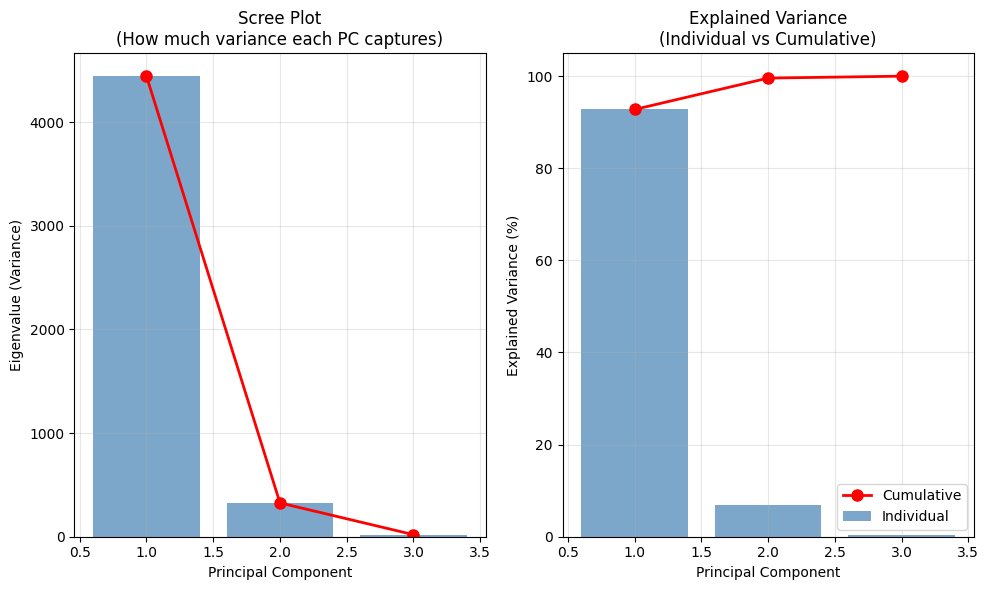

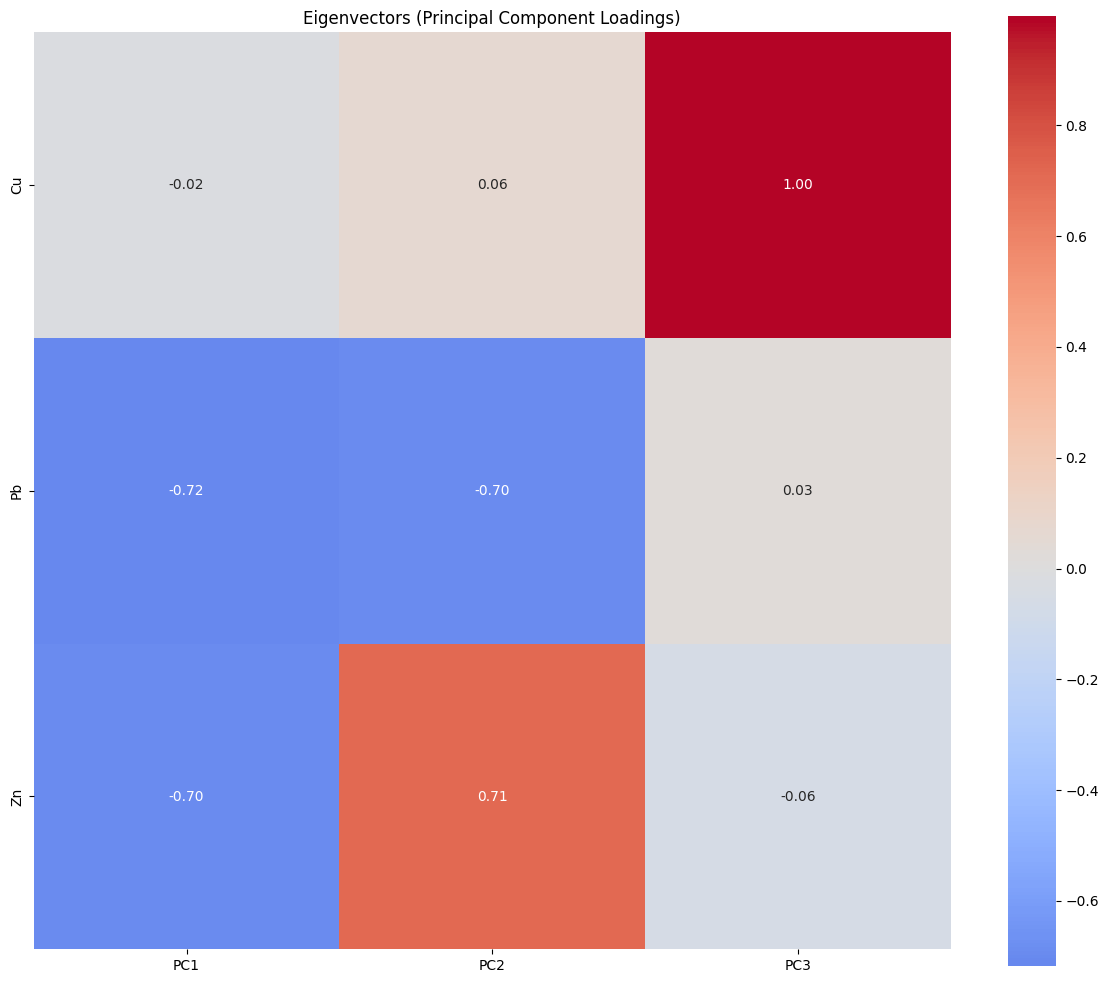

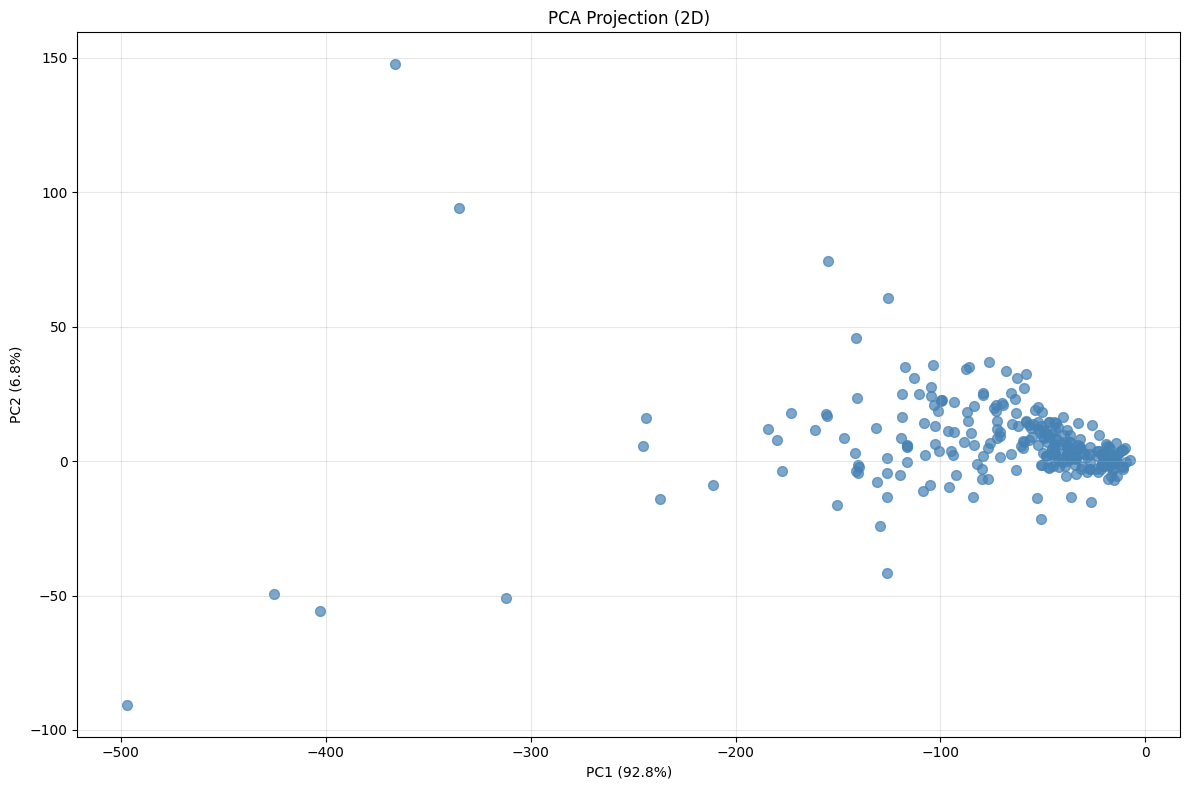

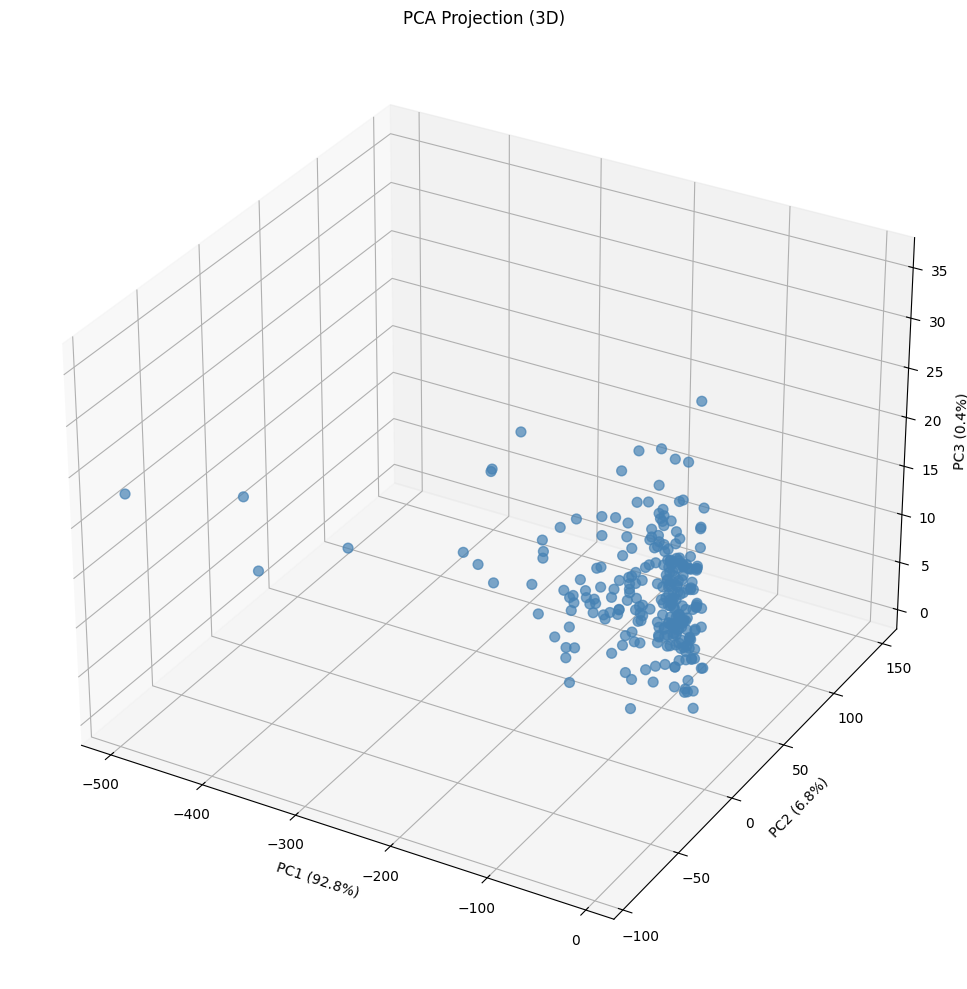


✅ PCA Analysis Complete!
   3 elements reduced to 3 principal components
   Variance explained: 100.0%

📈 INDIVIDUAL VISUALIZATIONS


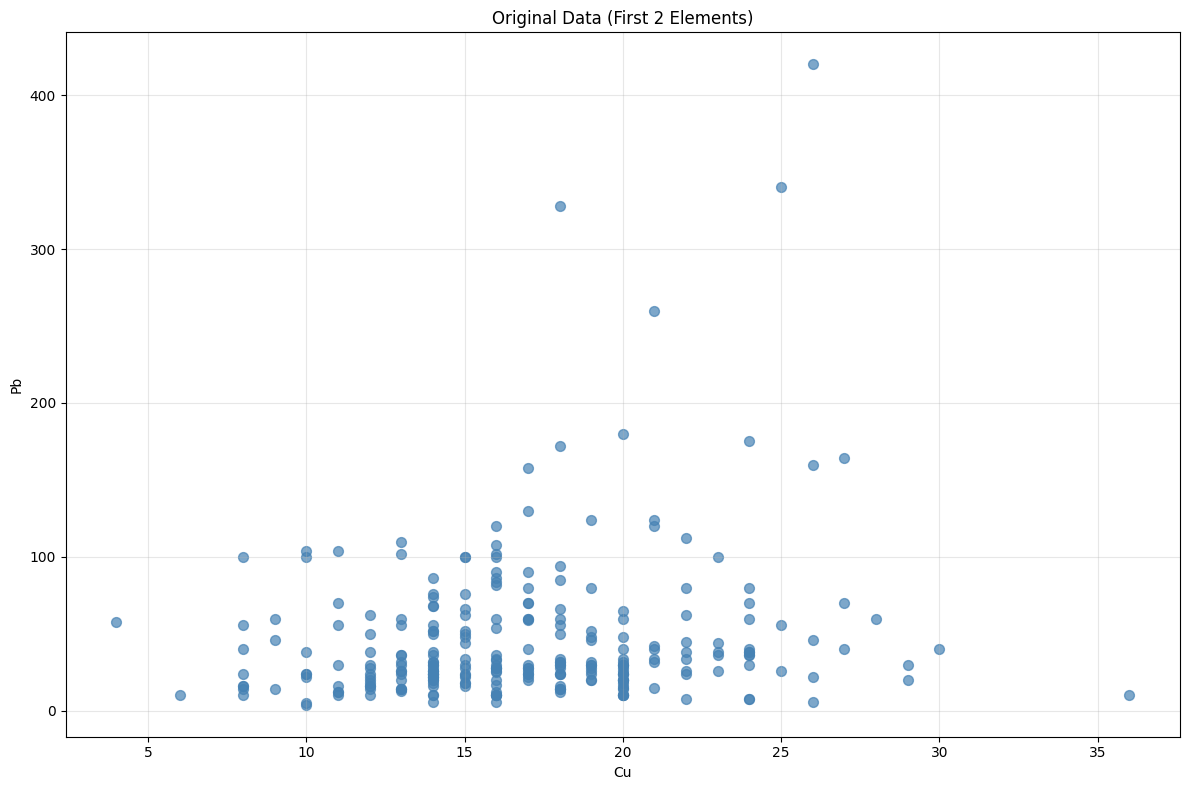

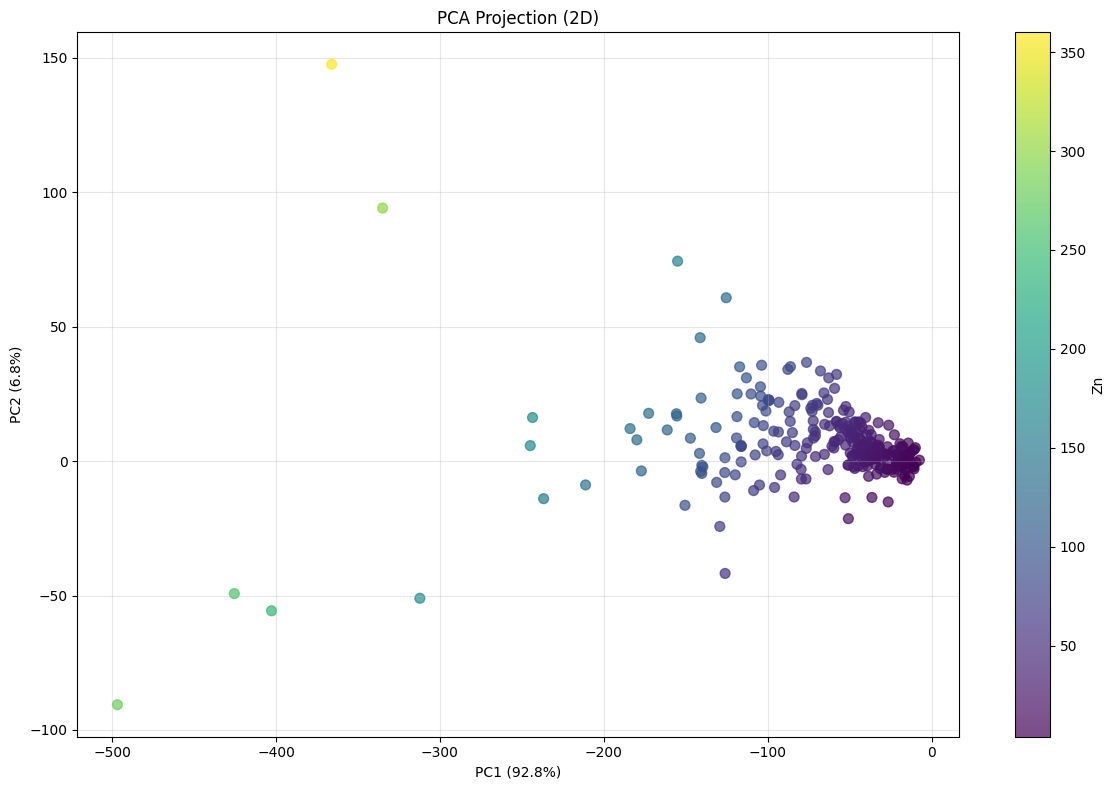


✅ ANALYSIS COMPLETE!


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

class Mouf:
    def __init__(self, df):
        self.df = df.copy()
        self.result = {}
        self.skip_cols = ['Sample', 'Sample_ID', 'ID', 'Lithology']
        self.numeric = []
        self.report = {}
        self.scaler = None
        self.X_centered = None
        self.cov_matrix = None
        self.eigenvalues = None
        self.eigenvectors = None
        self.X_pca = None
        self.explained_variance = None
        
        print("🔬 Mouf class initialized")

    # ============================================
    # 1. REMOVE FIRST ROW (PPM HEADER)
    # ============================================
    
    def remove_ppm(self, ppm=True):
        if ppm:
            self.df = self.df.iloc[1:].copy()
            print("✅ First row (PPM) is removed")
        else:
            print("⏭️ First row is kept")
        self.df = self.df.reset_index(drop=True)
        return self.df

    # ============================================
    # 2. CONVERT COLUMNS TO NUMERIC
    # ============================================
    
    def column_skip(self):
        conv_counted = 0
        skip_columns = []
        failed_columns = []

        for col in self.df.columns:
            if any(skip in col for skip in self.skip_cols):
                skip_columns.append(col)
                print(f"   ⏭️ Skipping: {col}")
                continue

            try:
                nm_columns = pd.to_numeric(self.df[col], errors='coerce')

                if nm_columns.notna().any():
                    self.df[col] = nm_columns
                    self.numeric.append(col)
                    conv_counted += 1
                    print(f"   ✅ Converted: {col}")
                else:
                    failed_columns.append(col)
                    print(f"   ⚠️ Failed: {col}")

            except Exception as e:
                failed_columns.append(col)
                print(f"   ❌ Error converting {col}: {e}")

        self.report['column_skip'] = conv_counted
        self.report['skipped_columns'] = skip_columns
        self.report['failed_columns'] = failed_columns
        
        print(f"\n✅ Converted {conv_counted} columns to numeric")
        print(f"   Numeric columns: {self.numeric}")
        
        return self.df

    # ============================================
    # 3. CENTER THE DATA
    # ============================================
    

    

    # ============================================
    # 4. COMPUTE COVARIANCE MATRIX
    # ============================================
    
    def compute_covariance(self):
        """
        Compute the covariance matrix.
        
        Mathematics:
        C = (1/(n-1)) × X_centeredᵀ × X_centered
        
        Where:
        - n = number of samples
        - X_centered = centered data
        """
        if self.X_centered is None:
            self.center_data()
        
        if self.X_centered is None:
            return None
        
        n = self.X_centered.shape[0]
        self.cov_matrix = (self.X_centered.T @ self.X_centered) / (n - 1)
        
        print(f"\n📊 Covariance Matrix")
        print(f"   Shape: {self.cov_matrix.shape}")
        
        # Print covariance matrix as DataFrame
        cov_df = pd.DataFrame(self.cov_matrix, 
                             index=self.numeric, 
                             columns=self.numeric)
        print("\nCovariance Matrix:")
        print(cov_df.round(4))
        
        return self.cov_matrix

    # ============================================
    # 5. COMPUTE EIGENVALUES AND EIGENVECTORS
    # ============================================
    
    def compute_eigen(self):
        """
        Compute eigenvalues and eigenvectors from covariance matrix.
        
        Mathematics:
        C × v = λ × v
        
        Where:
        - C = covariance matrix
        - v = eigenvector (principal component direction)
        - λ = eigenvalue (variance explained)
        """
        if self.cov_matrix is None:
            self.compute_covariance()
        
        if self.cov_matrix is None:
            return None, None
        
        # Compute eigenvalues and eigenvectors
        eigenvalues, eigenvectors = np.linalg.eigh(self.cov_matrix)
        
        # Sort by eigenvalues (largest first)
        idx = np.argsort(eigenvalues)[::-1]
        self.eigenvalues = eigenvalues[idx]
        self.eigenvectors = eigenvectors[:, idx]
        
        # Calculate explained variance
        self.explained_variance = self.eigenvalues / self.eigenvalues.sum()
        
        print(f"\n🔢 EIGENVALUES AND EIGENVECTORS")
        print("=" * 60)
        
        print("\nEigenvalues (variance captured):")
        for i, val in enumerate(self.eigenvalues):
            print(f"   λ{i+1} = {val:.4f} ({self.explained_variance[i]*100:.1f}% of total variance)")
        
        print("\nEigenvectors (principal component directions):")
        for i in range(len(self.eigenvalues)):
            print(f"\n   PC{i+1} = ", end="")
            loadings = []
            for j, elem in enumerate(self.numeric):
                loading = self.eigenvectors[j, i]
                sign = "+" if loading > 0 else "-"
                loadings.append(f"{sign} {abs(loading):.3f}×{elem}")
            print(" ".join(loadings))
        
        # Store in results
        self.result['eigenvalues'] = self.eigenvalues
        self.result['eigenvectors'] = self.eigenvectors
        self.result['explained_variance'] = self.explained_variance
        
        return self.eigenvalues, self.eigenvectors

    # ============================================
    # 6. PROJECT DATA ONTO PCA COMPONENTS
    # ============================================
    
    def project_pca(self, n_components=None):
        """
        Project data onto principal components.
        
        Mathematics:
        X_pca = X × V
        
        Where:
        - X = original data
        - V = eigenvectors (principal components)
        """
        if self.eigenvectors is None:
            self.compute_eigen()
        
        if self.eigenvectors is None:
            return None
        
        if n_components is None:
            n_components = len(self.eigenvalues)
        
        # Select top n_components
        V = self.eigenvectors[:, :n_components]
        
        # Extract data
        X = self.df[self.numeric].to_numpy(dtype=float)
        
        # Project
        self.X_pca = X @ V
        
        print(f"\n🔄 PCA Projection")
        print(f"   Original shape: {X.shape}")
        print(f"   PCA shape: {self.X_pca.shape}")
        
        return self.X_pca

    # ============================================
    # 7. VISUALIZATIONS
    # ============================================
    
    def plot_scree(self, figsize=(10, 6)):
        """
        Plot scree plot showing eigenvalues.
        """
        if self.eigenvalues is None:
            self.compute_eigen()
        
        if self.eigenvalues is None:
            return
        
        fig, axes = plt.subplots(1, 2, figsize=figsize)
        
        # Plot 1: Eigenvalues
        ax1 = axes[0]
        ax1.bar(range(1, len(self.eigenvalues)+1), self.eigenvalues, 
                color='steelblue', alpha=0.7)
        ax1.plot(range(1, len(self.eigenvalues)+1), self.eigenvalues, 
                'ro-', linewidth=2, markersize=8)
        ax1.set_xlabel('Principal Component')
        ax1.set_ylabel('Eigenvalue (Variance)')
        ax1.set_title('Scree Plot\n(How much variance each PC captures)')
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Explained variance
        ax2 = axes[1]
        cumsum = np.cumsum(self.explained_variance)
        ax2.bar(range(1, len(self.explained_variance)+1), 
                self.explained_variance * 100,
                color='steelblue', alpha=0.7, label='Individual')
        ax2.plot(range(1, len(self.explained_variance)+1), 
                cumsum * 100, 'ro-', linewidth=2, 
                markersize=8, label='Cumulative')
        ax2.set_xlabel('Principal Component')
        ax2.set_ylabel('Explained Variance (%)')
        ax2.set_title('Explained Variance\n(Individual vs Cumulative)')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_pca_2d(self, color_by=None, figsize=(12, 8)):
        """
        Plot PCA results in 2D.
        """
        if self.X_pca is None:
            self.project_pca(n_components=2)
        
        if self.X_pca is None or self.X_pca.shape[1] < 2:
            print("⚠️ Need at least 2 components for 2D plot")
            return
        
        fig, ax = plt.subplots(figsize=figsize)
        
        # Color by column
        if color_by is not None and color_by in self.df.columns:
            scatter = ax.scatter(self.X_pca[:, 0], self.X_pca[:, 1],
                                c=self.df[color_by], cmap='viridis',
                                alpha=0.7, s=50)
            plt.colorbar(scatter, ax=ax, label=color_by)
        else:
            ax.scatter(self.X_pca[:, 0], self.X_pca[:, 1],
                      alpha=0.7, s=50, color='steelblue')
        
        ax.set_xlabel(f'PC1 ({self.explained_variance[0]*100:.1f}%)')
        ax.set_ylabel(f'PC2 ({self.explained_variance[1]*100:.1f}%)')
        ax.set_title('PCA Projection (2D)')
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_pca_3d(self, figsize=(12, 10)):
        """
        Plot PCA results in 3D.
        """
        if self.X_pca is None:
            self.project_pca(n_components=3)
        
        if self.X_pca is None or self.X_pca.shape[1] < 3:
            print("⚠️ Need at least 3 components for 3D plot")
            return
        
        from mpl_toolkits.mplot3d import Axes3D
        
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111, projection='3d')
        
        ax.scatter(self.X_pca[:, 0], self.X_pca[:, 1], self.X_pca[:, 2],
                  alpha=0.7, s=50, color='steelblue')
        
        ax.set_xlabel(f'PC1 ({self.explained_variance[0]*100:.1f}%)')
        ax.set_ylabel(f'PC2 ({self.explained_variance[1]*100:.1f}%)')
        ax.set_zlabel(f'PC3 ({self.explained_variance[2]*100:.1f}%)')
        ax.set_title('PCA Projection (3D)')
        
        plt.tight_layout()
        plt.show()
    
    def plot_eigenvectors_heatmap(self, figsize=(12, 10)):
        """
        Plot eigenvectors as a heatmap.
        """
        if self.eigenvectors is None:
            self.compute_eigen()
        
        if self.eigenvectors is None:
            return
        
        eigen_df = pd.DataFrame(
            self.eigenvectors,
            index=self.numeric,
            columns=[f'PC{i+1}' for i in range(len(self.eigenvalues))]
        )
        
        plt.figure(figsize=figsize)
        sns.heatmap(eigen_df, annot=True, fmt='.2f', cmap='coolwarm',
                   center=0, square=True)
        plt.title('Eigenvectors (Principal Component Loadings)')
        plt.tight_layout()
        plt.show()
    
    def plot_original_data(self, figsize=(12, 8)):
        """
        Plot original data in 2D (first two elements).
        """
        if len(self.numeric) < 2:
            print("⚠️ Need at least 2 numeric columns")
            return
        
        fig, ax = plt.subplots(figsize=figsize)
        
        ax.scatter(self.df[self.numeric[0]], self.df[self.numeric[1]],
                  alpha=0.7, s=50, color='steelblue')
        
        ax.set_xlabel(self.numeric[0])
        ax.set_ylabel(self.numeric[1])
        ax.set_title('Original Data (First 2 Elements)')
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    # ============================================
    # 8. COMPLETE PCA ANALYSIS
    # ============================================
    
    def full_pca_analysis(self):
        """
        Run complete PCA analysis and generate all plots.
        """
        print("\n" + "=" * 70)
        print("📊 COMPLETE PCA ANALYSIS")
        print("=" * 70)
        
        # 1. Center data
        self.center_data()
        
        # 2. Compute covariance
        self.compute_covariance()
        
        # 3. Compute eigenvalues and eigenvectors
        self.compute_eigen()
        
        # 4. Project data
        self.project_pca(n_components=3)
        
        # 5. Generate plots
        self.plot_scree()
        self.plot_eigenvectors_heatmap()
        self.plot_pca_2d()
        self.plot_pca_3d()
        
        print("\n✅ PCA Analysis Complete!")
        print(f"   {len(self.numeric)} elements reduced to 3 principal components")
        print(f"   Variance explained: {self.explained_variance[:3].sum()*100:.1f}%")
        
        return self.result


# ============================================
# DEMONSTRATION
# ============================================

if __name__ == "__main__":

    print("=" * 70)
    print("🪨 MOUF PCA ANALYSIS")
    print("=" * 70)

    # 1. LOAD DATA
    df = pd.read_csv('test datat .csv')

    print("\n📊 Original Data:")
    print(df.head())
    print(f"\nShape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")

    # 2. CREATE MOUF INSTANCE
    analyzer = Mouf(df)

    # 3. REMOVE FIRST ROW (PPM HEADER)
    analyzer.remove_ppm(ppm=True)

    # 4. CONVERT TO NUMERIC
    analyzer.column_skip()

    # 5. RUN COMPLETE PCA ANALYSIS
    analyzer.full_pca_analysis()

    # 6. INDIVIDUAL VISUALIZATIONS
    print("\n" + "=" * 70)
    print("📈 INDIVIDUAL VISUALIZATIONS")
    print("=" * 70)

    # Plot original data
    analyzer.plot_original_data()

    # Plot PCA with color
    if 'Zn' in analyzer.df.columns:
        analyzer.plot_pca_2d(color_by='Zn')
    
    print("\n" + "=" * 70)
    print("✅ ANALYSIS COMPLETE!")
    print("=" * 70)

In [15]:
df = pd.read_csv('test datat .csv')
print(f'{df.info()}')
print(f'{df.columns}')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  267 non-null    object
 1   Cu      267 non-null    object
 2   Pb      267 non-null    object
 3   Zn      267 non-null    object
dtypes: object(4)
memory usage: 8.5+ KB
None
Index(['Sample', 'Cu', 'Pb', 'Zn'], dtype='object')


In [1]:
import pandas as pd
df = pd.read_csv('test datat .csv')
print(f'{df.info()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  267 non-null    object
 1   Cu      267 non-null    object
 2   Pb      267 non-null    object
 3   Zn      267 non-null    object
dtypes: object(4)
memory usage: 8.5+ KB
None


In [21]:
import pandas as pd
import numpy as np 

class Geo:
    def __init__(self, df):
        self.df = df.copy()
        self.results ={}
        self.report = {}
        self.skip_col = ['Sample']
    def row_remove(self, first_row = True):
        if first_row:
            self.df = self.df.iloc[1:]
            self.report['first_remove'] = True
            print('ppm_row is successfuly removed')
        else:
            print('failed')
        print({self.df.info()})
        return self.df
    def skip_cols(self):
        for col in columns:
            if any(skip in col for skip in self.skip_col):
                print()
                
                
cleaned_data = Geo(df)
cleaned_data.row_remove()
    

        

ppm_row is successfuly removed
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 1 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  266 non-null    object
 1   Cu      266 non-null    object
 2   Pb      266 non-null    object
 3   Zn      266 non-null    object
dtypes: object(4)
memory usage: 8.4+ KB
{None}


,Sample,Cu,Pb,Zn
1,1,14,26,35
2,2,12,24,30
3,3,16,28,35
4,4,16,28,40
5,5,10,24,24
...,...,...,...,...
262,262,23,38,33
263,263,20,24,19
264,264,24,40,72
265,265,29,20,62


In [ ]:
 def column_skip(self):
        conv_counted = 0
        skip_columns = []
        failed_columns = []

        for col in self.df.columns:
            if any(skip in col for skip in self.skip_cols):
                skip_columns.append(col)
                print(f"   ⏭️ Skipping: {col}")
                continue

            try:
                nm_columns = pd.to_numeric(self.df[col], errors='coerce')

                if nm_columns.notna().any():
                    self.df[col] = nm_columns
                    self.numeric.append(col)
                    conv_counted += 1
                    print(f"   ✅ Converted: {col}")
                else:
                    failed_columns.append(col)
                    print(f"   ⚠️ Failed: {col}")

            except Exception as e:
                failed_columns.append(col)
                print(f"   ❌ Error converting {col}: {e}")

        self.report['column_skip'] = conv_counted
        self.report['skipped_columns'] = skip_columns
        self.report['failed_columns'] = failed_columns
        
        print(f"\n✅ Converted {conv_counted} columns to numeric")
        print(f"   Numeric columns: {self.numeric}")
        
        return self.df
#In geoscience data, a column may contain mixed values, such as numeric assay data plus text like "below detection" or "n/a".
#This check helps keep useful columns while rejecting columns that became completely empty after conversion.

In [ ]:
what is your goal : 'clean the data through removing first row and convert text numeric column to real number'
what problems in column : column contain text, values less than detction limit, failing of conversion and handling errors
how to solve it: 
1.first I need to make tracking progress through creating container that help me to know:
a. how many columns were successfully converted to numeric
b. how many columns were failed 
c. how many column were skips 
2.first, we need to  define a method for columns filtering through function that contain the object self created
3. then we need to loop through all column names first, and skip the column names in the skip_columns

I have my df and need to convert it to numeric but the problem is some columns fail and stop the process of method
so I have to formulate logically through true and false the language of computer 
I need at least one column to be process if the other columns are text yhe computer logic for this should break down the thing to 
true and false 


In [4]:
class Prepare_data:
    def __init__(self):
        self.df = df.copy()
        self.report = {}
        self.skip_columns = [' Sample']
        self.numeric = []
    def first_row(self, f_row = True):
        if f_row:
            self.df = self.df.iloc[1:].copy
            print(f'unnecessary row or rows removed sucuessfully')
        else:
            print(f'first_row is exist')
            pass
        return self.df 
    def column_skip(self):
        converted_count = 0
        skip_columns = []
        failed_columns = []
        
        for col in self.skip_columns:
            #i need at least when column to be true (if any), item in column using match between data frame columns and columns need 
            #to skip through loopin through 'for item in self.skip_columns and convert ech column name into true and false and if any
            #finally check the true and false fro item in col and if find at least one true it contue with converted columns'
            if any(item in col for item in self.skip_columns):
                skip_columns.append(col) #save the skip column in tracking variable
                print('{col}')
                continue
            #try: This starts a safety block. It means: 
            #“attempt the conversion, and if something unexpected happens, handle it later instead of crashing the whole program.   
                try:
                nm_converted = pd.to_numeric(self.df[col], errors = 'coerce')
                if nm_converted.notna().any():
                    #this means after converting there is still problem with column like the column completely 'NAN', 
                    #so we need another condition to skip this column and proceed with the other
                    #if +any() at the end handle at least one is true but notna check the value of each converted columns and 
                    #and convert the value of columns to true and false if at least one is real number is assigned true to the column 
                    #and if any check the result and proceed
                    self.df[col] = nm_converted
                    self.numeric.append(col)
                    converted_count +=1
                    print(f'{col}')
                else:
                    failed_column.append(col)
                    #important not col has different mean based on the conditions
                    print(f'failed')

        return self.df
                
clen =   Prepare_data(df)
clen.first_row()
clen.column_skip()
                    


            
                
        
        
        

IndentationError: unindent does not match any outer indentation level (<string>, line 30)

In [8]:
import pandas as pd
import stats

class Prepare_data:
    def __init__(self, df):
        self.df = df.copy()
        self.report = {}
        self.skip_columns = ['Sample']
        self.numeric = []

    def first_row(self, f_row=True):
        if f_row:
            self.df = self.df.iloc[1:].copy()
            print("Unnecessary row(s) removed successfully")
        else:
            print("First row is kept")
        return self.df

    def column_skip(self):
        converted_count = 0
        skipped_columns = []
        failed_columns = []

        for col in self.df.columns:
            if any(item in col for item in self.skip_columns):
                skipped_columns.append(col)
                print(f"Skipping: {col}")
                continue

            try:
                nm_converted = pd.to_numeric(self.df[col], errors='coerce')

                if nm_converted.notna().any():
                    self.df[col] = nm_converted
                    self.numeric.append(col)
                    converted_count += 1
                    print(f"Converted: {col}")
                    print(f'{self.df.info()}')
                    print(f'{self.df.describe_stats()}'
                else:
                    failed_columns.append(col)
                    print(f"Failed: {col}")

            except Exception as e:
                failed_columns.append(col)
                print(f"Error converting {col}: {e}")

        self.report['converted_count'] = converted_count
        self.report['skipped_columns'] = skipped_columns
        self.report['failed_columns'] = failed_columns

        return self.df


clen = Prepare_data(df)
clen.first_row()
clen.column_skip()

Unnecessary row(s) removed successfully
Skipping: Sample
Converted: Cu
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 1 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  266 non-null    object
 1   Cu      266 non-null    int64 
 2   Pb      266 non-null    object
 3   Zn      266 non-null    object
dtypes: int64(1), object(3)
memory usage: 8.4+ KB
None
Converted: Pb
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 1 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  266 non-null    object
 1   Cu      266 non-null    int64 
 2   Pb      266 non-null    int64 
 3   Zn      266 non-null    object
dtypes: int64(2), object(2)
memory usage: 8.4+ KB
None
Converted: Zn
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 1 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------

,Sample,Cu,Pb,Zn
1,1,14,26,35
2,2,12,24,30
3,3,16,28,35
4,4,16,28,40
5,5,10,24,24
...,...,...,...,...
262,262,23,38,33
263,263,20,24,19
264,264,24,40,72
265,265,29,20,62


In [10]:
import pandas as pd

class Prepare_data:
    def __init__(self, df):
        self.df = df.copy()
        self.report = {}
        self.skip_columns = ['Sample']
        self.numeric = []

    def first_row(self, f_row=True):
        if f_row:
            self.df = self.df.iloc[1:].copy()
            print("Unnecessary row(s) removed successfully")
        else:
            print("First row is kept")
        return self.df

    def column_skip(self):
        converted_count = 0
        skipped_columns = []
        failed_columns = []

        for col in self.df.columns:
            if any(item in col for item in self.skip_columns):
                skipped_columns.append(col)
                print(f"Skipping: {col}")
                continue

            try:
                nm_converted = pd.to_numeric(self.df[col], errors='coerce')

                if nm_converted.notna().any():
                    self.df[col] = nm_converted
                    self.numeric.append(col)
                    converted_count += 1
                    print(f"Converted: {col}")
                    print(self.df.info())
                    print(self.df.describe())
                else:
                    failed_columns.append(col)
                    print(f"Failed: {col}")

            except Exception as e:
                failed_columns.append(col)
                print(f"Error converting {col}: {e}")

        self.report['converted_count'] = converted_count
        self.report['skipped_columns'] = skipped_columns
        self.report['failed_columns'] = failed_columns

        return self.df


clen = Prepare_data(df)
clen.first_row()
clen.column_skip()

Unnecessary row(s) removed successfully
Skipping: Sample
Converted: Cu
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 1 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  266 non-null    object
 1   Cu      266 non-null    int64 
 2   Pb      266 non-null    object
 3   Zn      266 non-null    object
dtypes: int64(1), object(3)
memory usage: 8.4+ KB
None
               Cu
count  266.000000
mean    16.890977
std      4.781189
min      4.000000
25%     14.000000
50%     16.000000
75%     20.000000
max     36.000000
Converted: Pb
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 266 entries, 1 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  266 non-null    object
 1   Cu      266 non-null    int64 
 2   Pb      266 non-null    int64 
 3   Zn      266 non-null    object
dtypes: int64(2), object(2)
memory usage: 8.4+ KB
None
   

,Sample,Cu,Pb,Zn
1,1,14,26,35
2,2,12,24,30
3,3,16,28,35
4,4,16,28,40
5,5,10,24,24
...,...,...,...,...
262,262,23,38,33
263,263,20,24,19
264,264,24,40,72
265,265,29,20,62


In [3]:
import pandas as pd 
import numpy as np

df = pd.read_csv('test datat .csv')
print(f'{df.info()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Sample  267 non-null    object
 1   Cu      267 non-null    object
 2   Pb      267 non-null    object
 3   Zn      267 non-null    object
dtypes: object(4)
memory usage: 8.5+ KB
None


In [15]:
import pandas as pd

class Kass:
    def __init__(self, df):
        self.df = df.copy()
        self.report = {}
        self.numeric = []
        self.skip_col = ['Sample']

    def removefirstr(self, f_row=True):
        if f_row:
            self.df = self.df.iloc[1:].copy()
            print("first row is removed")
        else:
            print("removal failed")

    def skip_text_column(self):
        numeric_count = 0
        failed_skip = []
        success_conversion = []

        for col in self.df.columns:
            if any(text in col for text in self.skip_col):
                failed_skip.append(col)
                print(col)
                continue

            convert_nm = pd.to_numeric(self.df[col], errors='coerce')

            if convert_nm.notna().any():
                self.df[col] = convert_nm
                print(convert_nm)
                success_conversion.append(col)
                self.numeric.append(col)
                numeric_count += 1
            else:
                print(f"{col} could not be converted")

        self.report["numeric_count"] = numeric_count
        self.report["failed_skip"] = failed_skip
        self.report["success_conversion"] = success_conversion
        return self.df

In [17]:
boh = Kass(df)
boh.removefirstr()
boh.skip_text_column()

first row is removed
Sample
1      14
2      12
3      16
4      16
5      10
       ..
262    23
263    20
264    24
265    29
266    30
Name: Cu, Length: 266, dtype: int64
1      26
2      24
3      28
4      28
5      24
       ..
262    38
263    24
264    40
265    20
266    40
Name: Pb, Length: 266, dtype: int64
1      35
2      30
3      35
4      40
5      24
       ..
262    33
263    19
264    72
265    62
266    84
Name: Zn, Length: 266, dtype: int64


,Sample,Cu,Pb,Zn
1,1,14,26,35
2,2,12,24,30
3,3,16,28,35
4,4,16,28,40
5,5,10,24,24
...,...,...,...,...
262,262,23,38,33
263,263,20,24,19
264,264,24,40,72
265,265,29,20,62


In [ ]:
def statitstic_analysis(self, columns = None):
    '''
    1. parameter columns = None : that means to give flexisibility and avoiding error,
    when the user provide does not provide column_names then the numeric_colummn should be 
    used by default.
    2. does not exist in the data, the object not fsiled to process. but it filter out the specifc column and go ahead with rest''' 
    
    if columns is None:
        columns = self.numeric
        
        

In [1]:
import pandas as pd
import numpy as np
from IPython.display import display

class Geo:
    """
    Geochemical Data Analysis Class
    
    A class for loading, exploring, and analyzing geochemical data.
    """
    
    def __init__(self, filepath=None, df=None):
        """
        Initialize the Geo class with data.
        
        Parameters:
        -----------
        filepath : str, optional
            Path to CSV file
        df : pandas DataFrame, optional
            Existing DataFrame
        """
        self.df = None
        self.raw_data = {}
        self.report = {}
        
        if filepath is not None:
            self.data_uploading(filepath)
        elif df is not None:
            self.df = df.copy()
            print(f"✅ Data loaded from DataFrame: {len(self.df)} rows")
        else:
            print("⚠️ No data provided. Use data_uploading() to load data.")
    
    # ============================================
    # 1. DATA UPLOADING
    # ============================================
    
    def data_uploading(self, filepath):
        """
        Load data from CSV file.
        
        Parameters:
        -----------
        filepath : str
            Path to CSV file
        """
        self.df = pd.read_csv(filepath)
        self.raw_data = self.df.copy()
        print(f"✅ Data loaded from: {filepath}")
        print(f"   Shape: {self.df.shape}")
        print(f"   Columns: {self.df.columns.tolist()}")
        return self.df
    
    # ============================================
    # 2. BASIC INFORMATION
    # ============================================
    
    def basic_info(self):
        """
        Display basic dataset information in a styled table.
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        basic_info = pd.DataFrame({
            'Property': [
                '📋 Number of Samples',
                '📋 Number of Columns',
                '📋 Shape',
                '💾 Memory Usage',
                '📊 Data Types',
                '🔍 Missing Values',
                '✅ Complete Rows'
            ],
            'Value': [
                f'{len(self.df):,}',
                f'{len(self.df.columns)}',
                f'{self.df.shape[0]:,} rows × {self.df.shape[1]} columns',
                f'{self.df.memory_usage(deep=True).sum() / 1024:.2f} KB',
                f'{self.df.dtypes.nunique()} unique types',
                f'{self.df.isna().sum().sum():,} missing',
                f'{len(self.df) - self.df.isna().any(axis=1).sum():,} rows'
            ]
        })
        
        styled_info = (
            basic_info.style
            .hide(axis="index")
            .set_caption("📁 DATASET SUMMARY")
            .set_table_styles([
                {'selector': 'caption', 'props': [
                    ('font-size', '18px'),
                    ('font-weight', 'bold'),
                    ('color', '#2c3e50'),
                    ('padding', '15px'),
                    ('background-color', '#ecf0f1')
                ]},
                {'selector': 'th', 'props': [
                    ('background-color', '#2c3e50'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'left'),
                    ('padding', '12px 15px'),
                    ('font-size', '14px')
                ]},
                {'selector': 'td', 'props': [
                    ('padding', '12px 15px'),
                    ('text-align', 'left'),
                    ('font-size', '13px'),
                    ('border-bottom', '1px solid #e0e0e0')
                ]},
                {'selector': 'table', 'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '60%'),
                    ('margin', '20px auto'),
                    ('border', '1px solid #d0d0d0'),
                    ('border-radius', '8px'),
                    ('box-shadow', '0 2px 8px rgba(0,0,0,0.1)')
                ]},
                {'selector': 'tr:nth-child(even)', 'props': [
                    ('background-color', '#f8f9fa')
                ]},
                {'selector': 'tr:nth-child(odd)', 'props': [
                    ('background-color', 'white')
                ]}
            ])
        )
        
        display(styled_info)
        return basic_info
    
    # ============================================
    # 3. COLUMN INFORMATION
    # ============================================
    
    def column_info(self):
        """
        Display detailed column information in a styled table.
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        def highlight_missing(row):
            """Highlight rows where 'Missing' > 0"""
            return ['background-color: #fff3cd' if row['Missing'] > 0 else '' for _ in row]
        
        column_info = pd.DataFrame({
            'Column Name': self.df.columns.tolist(),
            'Data Type': self.df.dtypes.values,
            'Non-Null': self.df.count().values,
            'Missing': self.df.isna().sum().values,
            'Missing %': (self.df.isna().sum().values / len(self.df) * 100).round(2),
            'Unique': [self.df[col].nunique() for col in self.df.columns],
            'Sample Values': [str(self.df[col].dropna().iloc[0]) if len(self.df[col].dropna()) > 0 else 'N/A' for col in self.df.columns]
        })
        
        styled_columns = (
            column_info.style
            .hide(axis="index")
            .set_caption("📊 COLUMN INFORMATION")
            .set_table_styles([
                {'selector': 'caption', 'props': [
                    ('font-size', '16px'),
                    ('font-weight', 'bold'),
                    ('color', '#2c3e50'),
                    ('padding', '12px'),
                    ('background-color', '#ecf0f1')
                ]},
                {'selector': 'th', 'props': [
                    ('background-color', '#34495e'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '10px 12px'),
                    ('font-size', '13px')
                ]},
                {'selector': 'td', 'props': [
                    ('padding', '10px 12px'),
                    ('text-align', 'center'),
                    ('font-size', '12px'),
                    ('border-bottom', '1px solid #e0e0e0')
                ]},
                {'selector': 'table', 'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '100%'),
                    ('margin', '10px auto'),
                    ('border', '1px solid #d0d0d0'),
                    ('border-radius', '6px'),
                    ('box-shadow', '0 2px 6px rgba(0,0,0,0.08)')
                ]},
                {'selector': 'tr:nth-child(even)', 'props': [
                    ('background-color', '#f8f9fa')
                ]}
            ])
            .apply(highlight_missing, axis=1)
        )
        
        display(styled_columns)
        return column_info
    
    # ============================================
    # 4. DATA TYPES SUMMARY
    # ============================================
    
    def dtype_summary(self):
        """
        Display data types distribution in a styled table.
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        dtype_summary = pd.DataFrame({
            'Data Type': self.df.dtypes.value_counts().index,
            'Count': self.df.dtypes.value_counts().values,
            'Percentage': (self.df.dtypes.value_counts().values / len(self.df.columns) * 100).round(1)
        })
        
        styled_dtypes = (
            dtype_summary.style
            .hide(axis="index")
            .set_caption("📊 DATA TYPES DISTRIBUTION")
            .set_table_styles([
                {'selector': 'caption', 'props': [
                    ('font-size', '16px'),
                    ('font-weight', 'bold'),
                    ('color', '#2c3e50'),
                    ('padding', '12px'),
                    ('background-color', '#ecf0f1')
                ]},
                {'selector': 'th', 'props': [
                    ('background-color', '#2c3e50'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '10px 15px')
                ]},
                {'selector': 'td', 'props': [
                    ('padding', '10px 15px'),
                    ('text-align', 'center'),
                    ('font-size', '13px')
                ]},
                {'selector': 'table', 'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '40%'),
                    ('margin', '10px auto'),
                    ('border', '1px solid #d0d0d0'),
                    ('border-radius', '6px')
                ]}
            ])
            .background_gradient(cmap='Blues', subset=['Count'])
        )
        
        display(styled_dtypes)
        return dtype_summary
    
    # ============================================
    # 5. MISSING VALUES ANALYSIS
    # ============================================
    
    def missing_values(self):
        """
        Display missing values analysis in a styled table.
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        def highlight_missing_pct(row):
            """Highlight rows where 'Missing %' > 0"""
            return ['background-color: #f8d7da' if row['Missing %'] > 0 else '' for _ in row]
        
        missing_summary = pd.DataFrame({
            'Column': self.df.columns.tolist(),
            'Missing Values': self.df.isna().sum().values,
            'Missing %': (self.df.isna().sum().values / len(self.df) * 100).round(2)
        })
        
        styled_missing = (
            missing_summary.style
            .hide(axis="index")
            .set_caption("🔍 MISSING VALUES SUMMARY")
            .set_table_styles([
                {'selector': 'caption', 'props': [
                    ('font-size', '16px'),
                    ('font-weight', 'bold'),
                    ('color', '#2c3e50'),
                    ('padding', '12px'),
                    ('background-color', '#ecf0f1')
                ]},
                {'selector': 'th', 'props': [
                    ('background-color', '#2c3e50'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '10px 15px')
                ]},
                {'selector': 'td', 'props': [
                    ('padding', '10px 15px'),
                    ('text-align', 'center'),
                    ('font-size', '13px')
                ]},
                {'selector': 'table', 'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '50%'),
                    ('margin', '10px auto'),
                    ('border', '1px solid #d0d0d0'),
                    ('border-radius', '6px')
                ]}
            ])
            .apply(highlight_missing_pct, axis=1)
        )
        
        display(styled_missing)
        return missing_summary
    
    # ============================================
    # 6. MEMORY USAGE
    # ============================================
    
    def memory_usage(self):
        """
        Display memory usage by column in a styled table.
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        memory_usage = self.df.memory_usage(deep=True)
        
        memory_table = pd.DataFrame({
            'Column': memory_usage.index.tolist(),
            'Memory (KB)': (memory_usage.values / 1024).round(2),
            'Memory %': ((memory_usage.values / memory_usage.sum()) * 100).round(1)
        })
        
        styled_memory = (
            memory_table.style
            .hide(axis="index")
            .set_caption("💾 MEMORY USAGE BY COLUMN")
            .set_table_styles([
                {'selector': 'caption', 'props': [
                    ('font-size', '16px'),
                    ('font-weight', 'bold'),
                    ('color', '#2c3e50'),
                    ('padding', '12px'),
                    ('background-color', '#ecf0f1')
                ]},
                {'selector': 'th', 'props': [
                    ('background-color', '#2c3e50'),
                    ('color', 'white'),
                    ('font-weight', 'bold'),
                    ('text-align', 'center'),
                    ('padding', '10px 15px')
                ]},
                {'selector': 'td', 'props': [
                    ('padding', '10px 15px'),
                    ('text-align', 'center'),
                    ('font-size', '13px')
                ]},
                {'selector': 'table', 'props': [
                    ('border-collapse', 'collapse'),
                    ('width', '50%'),
                    ('margin', '10px auto'),
                    ('border', '1px solid #d0d0d0'),
                    ('border-radius', '6px')
                ]}
            ])
            .background_gradient(cmap='Greens', subset=['Memory (KB)'])
        )
        
        display(styled_memory)
        return memory_table
    
    # ============================================
    # 7. SAMPLE DATA
    # ============================================
    
    def show_samples(self, n=5):
        """
        Display first and last n rows of the data.
        
        Parameters:
        -----------
        n : int, default=5
            Number of rows to display
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        print(f"\n📋 SAMPLE DATA (First {n} rows)")
        print("-" * 80)
        display(self.df.head(n))
        
        print(f"\n📋 SAMPLE DATA (Last {n} rows)")
        print("-" * 80)
        display(self.df.tail(n))
    
    # ============================================
    # 8. FULL EDA REPORT
    # ============================================
    
    def full_eda(self):
        """
        Run a complete Exploratory Data Analysis report.
        """
        if self.df is None:
            print("⚠️ No data loaded. Use data_uploading() first.")
            return
        
        print("=" * 80)
        print("📊 GEOCHEMICAL DATA EXPLORATION")
        print("=" * 80)
        
        self.basic_info()
        self.dtype_summary()
        self.missing_values()
        self.column_info()
        self.memory_usage()
        self.show_samples()
        
        print("\n" + "=" * 80)
        print("✅ EXPLORATION COMPLETE")
        print("=" * 80)


# ============================================
# DEMONSTRATION
# ============================================

if __name__ == "__main__":
    
    # Option 1: Load from file
    geo = Geo(filepath='test datat .csv')
    
    # Option 2: Load from existing DataFrame
    # df = pd.read_csv('test datat .csv')
    # geo = Geo(df=df)
    
    # Run full EDA
    geo.full_eda()
    
    # Or run individual methods
    # geo.basic_info()
    # geo.column_info()
    # geo.dtype_summary()
    # geo.missing_values()
    # geo.memory_usage()
    # geo.show_samples()

✅ Data loaded from: test datat .csv
   Shape: (267, 4)
   Columns: ['Sample', 'Cu', 'Pb', 'Zn']
📊 GEOCHEMICAL DATA EXPLORATION


Property,Value
📋 Number of Samples,267
📋 Number of Columns,4
📋 Shape,267 rows × 4 columns
💾 Memory Usage,53.50 KB
📊 Data Types,1 unique types
🔍 Missing Values,0 missing
✅ Complete Rows,267 rows


Data Type,Count,Percentage
object,4,100.000000


Column,Missing Values,Missing %
Sample,0,0.000000
Cu,0,0.000000
Pb,0,0.000000
Zn,0,0.000000


Column Name,Data Type,Non-Null,Missing,Missing %,Unique,Sample Values
Sample,object,267,0,0.000000,267,Number
Cu,object,267,0,0.000000,27,ppm
Pb,object,267,0,0.000000,72,ppm
Zn,object,267,0,0.000000,96,ppm


...


📋 SAMPLE DATA (First 5 rows)
--------------------------------------------------------------------------------


,Sample,Cu,Pb,Zn
0,Number,ppm,ppm,ppm
1,1,14,26,35
2,2,12,24,30
3,3,16,28,35
4,4,16,28,40



📋 SAMPLE DATA (Last 5 rows)
--------------------------------------------------------------------------------


,Sample,Cu,Pb,Zn
262,262,23,38,33
263,263,20,24,19
264,264,24,40,72
265,265,29,20,62
266,266,30,40,84



✅ EXPLORATION COMPLETE


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# FIX: Set style with error handling
# ============================================================

# Try different style names
try:
    plt.style.use('seaborn-v0-8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        try:
            plt.style.use('whitegrid')
        except OSError:
            # Fallback: use default style
            print("⚠️ Using default matplotlib style")
            pass

# Set seaborn style
try:
    sns.set_theme(style="whitegrid")
except:
    sns.set_style("whitegrid")

sns.set_palette("husl")

print("✅ Styles loaded successfully!")

class GeochemicalExplorer:
    """
    Complete Exploratory Geochemical Data Analysis
    
    Features:
    - Data cleaning and preprocessing
    - Descriptive statistics
    - Variance and covariance analysis
    - Multiple correlation methods (Pearson, Spearman, Kendall)
    - PCA (Principal Component Analysis)
    - Clustering and anomaly detection
    - Visualization suite
    """
    
    def __init__(self, df, element_columns=None, target=None):
        """
        Initialize the geochemical explorer.
        
        Parameters:
        -----------
        df : pandas DataFrame
            Geochemical data
        element_columns : list, optional
            List of element columns to analyze
        target : str, optional
            Target element for focused analysis
        """
        self.df = df.copy()
        self.original_df = df.copy()
        self.element_columns = ['Cu', 'Pb', 'Zn']
        self.target = target
        self.results = {}
        
        # Identify numeric columns
        if self.element_columns is None:
            self.element_columns = self.df.select_dtypes(include=[np.number]).columns.tolist()
        
        # Extract data matrix
        self.X = self.df[self.element_columns].to_numpy(dtype=float)
        self.n_samples, self.n_elements = self.X.shape
        
        print("=" * 70)
        print("🔬 GEOCHEMICAL EXPLORER INITIALIZED")
        print("=" * 70)
        print(f"   Samples: {self.n_samples}")
        print(f"   Elements: {self.n_elements}")
        print(f"   Columns: {self.element_columns}")
        print(f"   Target: {self.target}")
        print("-" * 60)
    
    # ============================================================
    # 1. DATA CLEANING
    # ============================================================
    
    def clean_data(self, remove_first_row=True, handle_outliers=True):
        """
        Clean the geochemical data.
        
        Parameters:
        -----------
        remove_first_row : bool
            Remove first row if it's a header
        handle_outliers : bool
            Cap outliers using IQR method
        """
        print("\n🧹 DATA CLEANING")
        print("=" * 60)
        
        # Remove first row if needed
        if remove_first_row:
            self.df = self.df.iloc[1:].copy()
            self.df = self.df.reset_index(drop=True)
            print("✅ First row removed")
        
        # Convert to numeric
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        # Remove rows with NaN
        before = len(self.df)
        self.df = self.df.dropna()
        after = len(self.df)
        print(f"✅ Dropped {before - after} rows with missing values")
        
        # Handle outliers
        if handle_outliers:
            for col in self.element_columns:
                if col in self.df.columns:
                    data = self.df[col]
                    Q1 = data.quantile(0.25)
                    Q3 = data.quantile(0.75)
                    IQR = Q3 - Q1
                    lower = Q1 - 1.5 * IQR
                    upper = Q3 + 1.5 * IQR
                    self.df[col] = data.clip(lower=lower, upper=upper)
            print("✅ Outliers capped")
        
        # Update data matrix
        self.X = self.df[self.element_columns].to_numpy(dtype=float)
        self.n_samples, self.n_elements = self.X.shape
        
        print(f"✅ Final shape: {self.n_samples} samples, {self.n_elements} elements")
        return self.df
    
    # ============================================================
    # 2. DESCRIPTIVE STATISTICS
    # ============================================================
    
    def descriptive_statistics(self):
        """
        Calculate comprehensive descriptive statistics.
        """
        print("\n📊 DESCRIPTIVE STATISTICS")
        print("=" * 60)
        
        stats_df = self.df[self.element_columns].describe().T
        
        # Add additional statistics
        stats_df['variance'] = self.df[self.element_columns].var()
        stats_df['skew'] = self.df[self.element_columns].skew()
        stats_df['kurtosis'] = self.df[self.element_columns].kurtosis()
        stats_df['cv'] = stats_df['std'] / stats_df['mean']  # Coefficient of variation
        
        self.results['descriptive_stats'] = stats_df
        
        print(stats_df.round(4))
        return stats_df
    
    # ============================================================
    # 3. VARIANCE ANALYSIS
    # ============================================================
    
    def variance_analysis(self):
        """
        Analyze variance of each element.
        """
        print("\n📈 VARIANCE ANALYSIS")
        print("=" * 60)
        
        variance = self.df[self.element_columns].var()
        std_dev = self.df[self.element_columns].std()
        cv = std_dev / self.df[self.element_columns].mean()
        
        variance_df = pd.DataFrame({
            'Variance': variance,
            'Std_Dev': std_dev,
            'CV': cv
        }).sort_values('Variance', ascending=False)
        
        self.results['variance'] = variance_df
        
        print(variance_df.round(4))
        
        # Identify high variance elements
        high_var = variance_df[variance_df['CV'] > 1]
        if len(high_var) > 0:
            print("\n⚠️ High Variability Elements (CV > 1):")
            print(high_var)
        
        return variance_df
    
    # ============================================================
    # 4. COVARIANCE ANALYSIS
    # ============================================================
    
    def covariance_analysis(self):
        """
        Calculate covariance matrix.
        """
        print("\n📊 COVARIANCE MATRIX")
        print("=" * 60)
        
        cov_matrix = self.df[self.element_columns].cov()
        self.results['covariance'] = cov_matrix
        
        print(cov_matrix.round(4))
        
        # Find strongest covariances
        strong_cov = []
        for i in range(len(cov_matrix.columns)):
            for j in range(i+1, len(cov_matrix.columns)):
                cov_val = cov_matrix.iloc[i, j]
                if abs(cov_val) > 1:
                    strong_cov.append({
                        'Elements': f"{cov_matrix.columns[i]} - {cov_matrix.columns[j]}",
                        'Covariance': cov_val
                    })
        
        if strong_cov:
            print("\n🔗 Strongest Covariances:")
            strong_df = pd.DataFrame(strong_cov).sort_values('Covariance', ascending=False)
            print(strong_df.head(5))
        
        return cov_matrix
    
    # ============================================================
    # 5. CORRELATION ANALYSIS (Multiple Methods)
    # ============================================================
    
    def correlation_analysis(self):
        """
        Calculate correlations using multiple methods:
        - Pearson (linear)
        - Spearman (monotonic)
        - Kendall (ordinal)
        """
        print("\n🔗 CORRELATION ANALYSIS")
        print("=" * 60)
        
        # 1. Pearson Correlation (Linear)
        pearson_corr = self.df[self.element_columns].corr(method='pearson')
        self.results['pearson_correlation'] = pearson_corr
        
        # 2. Spearman Correlation (Monotonic)
        spearman_corr = self.df[self.element_columns].corr(method='spearman')
        self.results['spearman_correlation'] = spearman_corr
        
        # 3. Kendall Correlation (Ordinal)
        kendall_corr = self.df[self.element_columns].corr(method='kendall')
        self.results['kendall_correlation'] = kendall_corr
        
        print("\n📊 Correlation Methods Comparison:")
        print(f"  Pearson:  Linear relationships (parametric)")
        print(f"  Spearman: Monotonic relationships (non-parametric)")
        print(f"  Kendall:  Ordinal relationships (non-parametric)")
        
        # Find strong correlations
        strong_pearson = self._find_strong_correlations(pearson_corr, 'Pearson')
        strong_spearman = self._find_strong_correlations(spearman_corr, 'Spearman')
        
        print("\n🔗 Strongest Correlations:")
        print("\nPearson (Linear):")
        for pair in strong_pearson[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        print("\nSpearman (Monotonic):")
        for pair in strong_spearman[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        return pearson_corr, spearman_corr, kendall_corr
    
    def _find_strong_correlations(self, corr_matrix, method):
        """Find strong correlations (|r| > 0.7)"""
        strong = []
        for i in range(len(corr_matrix.columns)):
            for j in range(i+1, len(corr_matrix.columns)):
                corr_val = corr_matrix.iloc[i, j]
                if abs(corr_val) > 0.7:
                    strong.append({
                        'Elements': f"{corr_matrix.columns[i]} - {corr_matrix.columns[j]}",
                        'Correlation': corr_val,
                        'Method': method
                    })
        return sorted(strong, key=lambda x: abs(x['Correlation']), reverse=True)
    
    # ============================================================
    # 6. TARGET CORRELATION ANALYSIS
    # ============================================================
    
    def target_correlation(self, target=None):
        """
        Analyze correlations with a specific target element.
        """
        if target is None:
            target = self.target
        
        if target is None:
            print("⚠️ No target specified")
            return None
        
        if target not in self.element_columns:
            print(f"⚠️ Target '{target}' not found in data")
            return None
        
        print(f"\n🎯 TARGET CORRELATION: {target}")
        print("=" * 60)
        
        target_correlations = {}
        
        for col in self.element_columns:
            if col == target:
                continue
            # Pearson
            pearson_r, pearson_p = pearsonr(self.df[target], self.df[col])
            # Spearman
            spearman_r, spearman_p = spearmanr(self.df[target], self.df[col])
            # Kendall
            kendall_r, kendall_p = kendalltau(self.df[target], self.df[col])
            
            target_correlations[col] = {
                'Pearson_r': pearson_r,
                'Pearson_p': pearson_p,
                'Spearman_r': spearman_r,
                'Spearman_p': spearman_p,
                'Kendall_r': kendall_r,
                'Kendall_p': kendall_p
            }
        
        # Convert to DataFrame
        corr_df = pd.DataFrame(target_correlations).T
        corr_df = corr_df.sort_values('Pearson_r', ascending=False)
        
        self.results['target_correlations'] = corr_df
        
        print(corr_df.round(4))
        
        # Identify observers (strong positive or negative)
        strong_observers = corr_df[abs(corr_df['Pearson_r']) > 0.5]
        if len(strong_observers) > 0:
            print("\n👁️ Strong Observers (|r| > 0.5):")
            for col, row in strong_observers.iterrows():
                direction = "positive" if row['Pearson_r'] > 0 else "negative"
                print(f"  {col}: {row['Pearson_r']:.3f} ({direction})")
        
        return corr_df
    
    # ============================================================
    # 7. PCA (Principal Component Analysis)
    # ============================================================
    
    def pca_analysis(self, n_components=None):
        """
        Perform PCA for dimensionality reduction.
        """
        print("\n🔄 PCA (Principal Component Analysis)")
        print("=" * 60)
        
        # Standardize data
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        # Determine number of components
        if n_components is None:
            n_components = min(self.n_elements, 10)
        
        # Perform PCA
        pca = PCA(n_components=n_components)
        X_pca = pca.fit_transform(X_scaled)
        
        # Explained variance
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = np.cumsum(explained_variance)
        
        # Store results
        self.results['pca'] = {
            'components': X_pca,
            'explained_variance': explained_variance,
            'cumulative_variance': cumulative_variance,
            'loadings': pca.components_,
            'n_components': n_components
        }
        
        print(f"\n📊 Explained Variance:")
        for i, (var, cum) in enumerate(zip(explained_variance, cumulative_variance)):
            print(f"  PC{i+1}: {var*100:.1f}% (cumulative: {cum*100:.1f}%)")
        
        # Determine optimal number of components
        n_optimal = np.argmax(cumulative_variance > 0.85) + 1
        print(f"\n🎯 Optimal number of components (85% variance): {n_optimal}")
        
        # Interpret PCA loadings
        print("\n🔍 PCA Component Interpretation (Top 3 components):")
        for i in range(min(3, n_components)):
            loadings = pca.components_[i]
            top_features = self.element_columns[np.argsort(np.abs(loadings))[::-1][:3]]
            print(f"\n  PC{i+1}:")
            for feat in top_features:
                idx = self.element_columns.index(feat)
                print(f"    {feat}: {loadings[idx]:.3f}")
        
        return X_pca, pca
    
    # ============================================================
    # 8. CLUSTERING ANALYSIS
    # ============================================================
    
    def cluster_analysis(self, n_clusters=3):
        """
        Perform K-means clustering on the data.
        """
        print(f"\n🧩 CLUSTERING ANALYSIS (K={n_clusters})")
        print("=" * 60)
        
        # Standardize data
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        # K-means clustering
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        clusters = kmeans.fit_predict(X_scaled)
        self.df['Cluster'] = clusters
        
        # Analyze clusters
        cluster_stats = self.df.groupby('Cluster')[self.element_columns].mean()
        
        print("\n📊 Cluster Characteristics:")
        print(cluster_stats.round(2))
        
        # Identify distinct clusters
        print("\n🔍 Distinct Element Signatures:")
        for cluster in range(n_clusters):
            cluster_data = self.df[self.df['Cluster'] == cluster][self.element_columns]
            cluster_means = cluster_data.mean()
            global_means = self.df[self.element_columns].mean()
            diff = cluster_means - global_means
            
            enriched = diff[diff > 0].sort_values(ascending=False).head(3)
            depleted = diff[diff < 0].sort_values(ascending=True).head(3)
            
            print(f"\n  Cluster {cluster} ({len(cluster_data)} samples):")
            if len(enriched) > 0:
                enriched_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in enriched.index])
                print(f"    Enriched: {enriched_str}")
            if len(depleted) > 0:
                depleted_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in depleted.index])
                print(f"    Depleted: {depleted_str}")
        
        self.results['clusters'] = kmeans
        return clusters, kmeans
    
    # ============================================================
    # 9. VISUALIZATION
    # ============================================================
    
    def plot_distributions(self, columns=None):
        """Plot distributions of elements."""
        if columns is None:
            columns = self.element_columns[:6]
        
        n_cols = min(3, len(columns))
        n_rows = (len(columns) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        axes = axes.flatten() if n_rows * n_cols > 1 else [axes]
        
        for i, col in enumerate(columns):
            if i < len(axes):
                ax = axes[i]
                data = self.df[col].dropna()
                
                ax.hist(data, bins=30, density=True, alpha=0.6, color='steelblue', edgecolor='black')
                
                # Add KDE
                from scipy.stats import gaussian_kde
                if len(data) > 1:
                    kde = gaussian_kde(data)
                    x_range = np.linspace(data.min(), data.max(), 100)
                    ax.plot(x_range, kde(x_range), 'r-', linewidth=2)
                
                ax.axvline(data.mean(), color='red', linestyle='--', label=f'Mean: {data.mean():.2f}')
                ax.axvline(data.median(), color='green', linestyle='--', label=f'Median: {data.median():.2f}')
                ax.set_xlabel(col)
                ax.set_ylabel('Density')
                ax.set_title(f'Distribution: {col}')
                ax.legend()
                ax.grid(True, alpha=0.3)
        
        plt.suptitle('Element Distributions', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_correlation_matrix(self, method='pearson'):
        """Plot correlation matrix heatmap."""
        corr_matrix = self.df[self.element_columns].corr(method=method)
        
        plt.figure(figsize=(12, 10))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
        sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
                   cmap='coolwarm', center=0, square=True,
                   linewidths=0.5, cbar_kws={"shrink": 0.8})
        plt.title(f'Correlation Matrix ({method.capitalize()})', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_pca(self):
        """Plot PCA results."""
        if 'pca' not in self.results:
            self.pca_analysis()
        
        pca_data = self.results['pca']
        X_pca = pca_data['components']
        explained_variance = pca_data['explained_variance']
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Scree plot
        ax1 = axes[0]
        components = range(1, len(explained_variance) + 1)
        ax1.bar(components, explained_variance * 100, color='steelblue', alpha=0.7)
        ax1.plot(components, pca_data['cumulative_variance'] * 100, 
                'ro-', linewidth=2, label='Cumulative')
        ax1.set_xlabel('Principal Component')
        ax1.set_ylabel('Explained Variance (%)')
        ax1.set_title('Scree Plot')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # PCA 2D projection
        ax2 = axes[1]
        if X_pca.shape[1] >= 2:
            if 'Cluster' in self.df.columns:
                scatter = ax2.scatter(X_pca[:, 0], X_pca[:, 1], 
                                    c=self.df['Cluster'], cmap='viridis', alpha=0.7)
                plt.colorbar(scatter, ax=ax2, label='Cluster')
            else:
                ax2.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=30)
            ax2.set_xlabel(f'PC1 ({explained_variance[0]*100:.1f}%)')
            ax2.set_ylabel(f'PC2 ({explained_variance[1]*100:.1f}%)')
            ax2.set_title('PCA Projection')
            ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_target_relationships(self, target=None):
        """Plot relationships with target element."""
        if target is None:
            target = self.target
        
        if target is None or target not in self.element_columns:
            print("⚠️ No valid target specified")
            return
        
        # Find top correlated elements
        if 'target_correlations' in self.results:
            corr_df = self.results['target_correlations']
            top_corr = corr_df.nlargest(4, 'Pearson_r').index.tolist()
        else:
            top_corr = [col for col in self.element_columns if col != target][:4]
        
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes = axes.flatten()
        
        for i, col in enumerate(top_corr[:4]):
            ax = axes[i]
            ax.scatter(self.df[col], self.df[target], alpha=0.6, s=30)
            
            # Add trend line
            z = np.polyfit(self.df[col], self.df[target], 1)
            p = np.poly1d(z)
            x_line = np.linspace(self.df[col].min(), self.df[col].max(), 100)
            ax.plot(x_line, p(x_line), 'r-', linewidth=2)
            
            # Add correlation
            corr = pearsonr(self.df[col], self.df[target])[0]
            ax.set_xlabel(col)
            ax.set_ylabel(target)
            ax.set_title(f'{col} vs {target} (r={corr:.3f})')
            ax.grid(True, alpha=0.3)
        
        plt.suptitle(f'Relationships with Target: {target}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    # ============================================================
    # 10. COMPLETE REPORT
    # ============================================================
    
    def full_report(self):
        """
        Generate a complete analysis report.
        """
        print("\n" + "█" * 70)
        print("📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT")
        print("█" * 70)
        
        # 1. Dataset overview
        print("\n📁 DATASET OVERVIEW:")
        print(f"  Samples: {self.n_samples}")
        print(f"  Elements: {self.n_elements}")
        print(f"  Columns: {self.element_columns}")
        
        # 2. Descriptive statistics
        stats = self.descriptive_statistics()
        
        # 3. Variance analysis
        variance = self.variance_analysis()
        
        # 4. Correlation analysis
        self.correlation_analysis()
        
        # 5. Target correlation (if target specified)
        if self.target:
            self.target_correlation()
        
        # 6. PCA
        self.pca_analysis()
        
        # 7. Clustering
        self.cluster_analysis()
        
        print("\n" + "█" * 70)
        print("✅ REPORT COMPLETE")
        print("█" * 70)
    
    # ============================================================
    # 11. EXPORT
    # ============================================================
    
    def export_results(self, filename="geochemical_analysis.xlsx"):
        """Export results to Excel."""
        with pd.ExcelWriter(filename) as writer:
            for key, value in self.results.items():
                if isinstance(value, pd.DataFrame):
                    value.to_excel(writer, sheet_name=key[:31])
        
        print(f"✅ Results exported to {filename}")


# ============================================================
# DEMONSTRATION
# ============================================================

if __name__ == "__main__":
    
    # Load data
    df = pd.read_csv('Brazildata.csv', encoding = 'cp1252')
    
    # Initialize explorer
    explorer = GeochemicalExplorer(df, target='Cu')
    
    # Clean data
    explorer.clean_data(remove_first_row=True, handle_outliers=True)
    
    # Full analysis
    explorer.full_report()
    
    # Visualizations
    explorer.plot_distributions()
    explorer.plot_correlation_matrix('pearson')
    explorer.plot_pca()
    explorer.plot_target_relationships()
    
    # Export results
    explorer.export_results()

⚠️ Using default matplotlib style
✅ Styles loaded successfully!


ValueError: could not convert string to float: 'ppm'

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# FIX: Set style with error handling
# ============================================================

# Try different style names
try:
    plt.style.use('seaborn-v0-8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        try:
            plt.style.use('whitegrid')
        except OSError:
            print("⚠️ Using default matplotlib style")
            pass

# Set seaborn style
try:
    sns.set_theme(style="whitegrid")
except:
    sns.set_style("whitegrid")

sns.set_palette("husl")

print("✅ Styles loaded successfully!")

class GeochemicalExplorer:
    """
    Complete Exploratory Geochemical Data Analysis
    
    Features:
    - Data cleaning and preprocessing
    - Descriptive statistics
    - Variance and covariance analysis
    - Multiple correlation methods (Pearson, Spearman, Kendall)
    - PCA (Principal Component Analysis)
    - Clustering and anomaly detection
    - Visualization suite
    """
    
    def __init__(self, df, element_columns=None, target=None):
        """
        Initialize the geochemical explorer.
        
        Parameters:
        -----------
        df : pandas DataFrame
            Geochemical data
        element_columns : list, optional
            List of element columns to analyze
        target : str, optional
            Target element for focused analysis
        """
        self.df = df.copy()
        self.original_df = df.copy()
        self.element_columns = element_columns
        self.target = target
        self.results = {}
        
        # 🔧 FIX: Clean data BEFORE identifying numeric columns
        self._clean_data_initial()
        
        # Identify numeric columns
        if self.element_columns is None:
            self.element_columns = self.df.select_dtypes(include=[np.number]).columns.tolist()
        
        # Extract data matrix
        if len(self.element_columns) > 0:
            self.X = self.df[self.element_columns].to_numpy(dtype=float)
        else:
            self.X = np.array([]).reshape(len(self.df), 0)
            print("⚠️ No numeric columns found!")
        
        self.n_samples, self.n_elements = self.X.shape if len(self.X) > 0 else (len(self.df), 0)
        
        print("=" * 70)
        print("🔬 GEOCHEMICAL EXPLORER INITIALIZED")
        print("=" * 70)
        print(f"   Samples: {self.n_samples}")
        print(f"   Elements: {self.n_elements}")
        print(f"   Columns: {self.element_columns}")
        print(f"   Target: {self.target}")
        print("-" * 60)
    
    def _clean_data_initial(self):
        """
        🔧 Initial data cleaning to handle 'ppm' strings and non-numeric values.
        """
        # Remove rows that contain 'ppm' in any column (header rows)
        for col in self.df.columns:
            if self.df[col].dtype == 'object':
                mask = self.df[col].astype(str).str.lower() == 'ppm'
                if mask.any():
                    self.df = self.df[~mask]
                    print(f"✅ Removed rows containing 'ppm' in column: {col}")
                    break
        
        # Convert all columns to numeric, coercing errors to NaN
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        # Reset index
        self.df = self.df.reset_index(drop=True)
    
    # ============================================================
    # 1. DATA CLEANING
    # ============================================================
    
    def clean_data(self, remove_first_row=True, handle_outliers=True):
        """
        Clean the geochemical data.
        
        Parameters:
        -----------
        remove_first_row : bool
            Remove first row if it's a header
        handle_outliers : bool
            Cap outliers using IQR method
        """
        print("\n🧹 DATA CLEANING")
        print("=" * 60)
        
        # Remove first row if needed
        if remove_first_row and len(self.df) > 0:
            self.df = self.df.iloc[1:].copy()
            self.df = self.df.reset_index(drop=True)
            print("✅ First row removed")
        
        # Convert to numeric
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        # Remove rows with NaN
        before = len(self.df)
        self.df = self.df.dropna()
        after = len(self.df)
        print(f"✅ Dropped {before - after} rows with missing values")
        
        # Handle outliers
        if handle_outliers:
            for col in self.element_columns:
                if col in self.df.columns:
                    data = self.df[col]
                    Q1 = data.quantile(0.25)
                    Q3 = data.quantile(0.75)
                    IQR = Q3 - Q1
                    lower = Q1 - 1.5 * IQR
                    upper = Q3 + 1.5 * IQR
                    self.df[col] = data.clip(lower=lower, upper=upper)
            print("✅ Outliers capped")
        
        # Update data matrix
        if len(self.element_columns) > 0:
            self.X = self.df[self.element_columns].to_numpy(dtype=float)
        else:
            self.X = np.array([]).reshape(len(self.df), 0)
        self.n_samples, self.n_elements = self.X.shape if len(self.X) > 0 else (len(self.df), 0)
        
        print(f"✅ Final shape: {self.n_samples} samples, {self.n_elements} elements")
        return self.df
    
    # ============================================================
    # 2. DESCRIPTIVE STATISTICS
    # ============================================================
    
    def descriptive_statistics(self):
        """
        Calculate comprehensive descriptive statistics.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return None
        
        print("\n📊 DESCRIPTIVE STATISTICS")
        print("=" * 60)
        
        stats_df = self.df[self.element_columns].describe().T
        
        # Add additional statistics
        stats_df['variance'] = self.df[self.element_columns].var()
        stats_df['skew'] = self.df[self.element_columns].skew()
        stats_df['kurtosis'] = self.df[self.element_columns].kurtosis()
        stats_df['cv'] = stats_df['std'] / stats_df['mean']  # Coefficient of variation
        
        self.results['descriptive_stats'] = stats_df
        
        print(stats_df.round(4))
        return stats_df
    
    # ============================================================
    # 3. VARIANCE ANALYSIS
    # ============================================================
    
    def variance_analysis(self):
        """
        Analyze variance of each element.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return None
        
        print("\n📈 VARIANCE ANALYSIS")
        print("=" * 60)
        
        variance = self.df[self.element_columns].var()
        std_dev = self.df[self.element_columns].std()
        cv = std_dev / self.df[self.element_columns].mean()
        
        variance_df = pd.DataFrame({
            'Variance': variance,
            'Std_Dev': std_dev,
            'CV': cv
        }).sort_values('Variance', ascending=False)
        
        self.results['variance'] = variance_df
        
        print(variance_df.round(4))
        
        # Identify high variance elements
        high_var = variance_df[variance_df['CV'] > 1]
        if len(high_var) > 0:
            print("\n⚠️ High Variability Elements (CV > 1):")
            print(high_var)
        
        return variance_df
    
    # ============================================================
    # 4. COVARIANCE ANALYSIS
    # ============================================================
    
    def covariance_analysis(self):
        """
        Calculate covariance matrix.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for covariance analysis")
            return None
        
        print("\n📊 COVARIANCE MATRIX")
        print("=" * 60)
        
        cov_matrix = self.df[self.element_columns].cov()
        self.results['covariance'] = cov_matrix
        
        print(cov_matrix.round(4))
        
        # Find strongest covariances
        strong_cov = []
        for i in range(len(cov_matrix.columns)):
            for j in range(i+1, len(cov_matrix.columns)):
                cov_val = cov_matrix.iloc[i, j]
                if abs(cov_val) > 1:
                    strong_cov.append({
                        'Elements': f"{cov_matrix.columns[i]} - {cov_matrix.columns[j]}",
                        'Covariance': cov_val
                    })
        
        if strong_cov:
            print("\n🔗 Strongest Covariances:")
            strong_df = pd.DataFrame(strong_cov).sort_values('Covariance', ascending=False)
            print(strong_df.head(5))
        
        return cov_matrix
    
    # ============================================================
    # 5. CORRELATION ANALYSIS (Multiple Methods)
    # ============================================================
    
    def correlation_analysis(self):
        """
        Calculate correlations using multiple methods:
        - Pearson (linear)
        - Spearman (monotonic)
        - Kendall (ordinal)
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation analysis")
            return None, None, None
        
        print("\n🔗 CORRELATION ANALYSIS")
        print("=" * 60)
        
        # 1. Pearson Correlation (Linear)
        pearson_corr = self.df[self.element_columns].corr(method='pearson')
        self.results['pearson_correlation'] = pearson_corr
        
        # 2. Spearman Correlation (Monotonic)
        spearman_corr = self.df[self.element_columns].corr(method='spearman')
        self.results['spearman_correlation'] = spearman_corr
        
        # 3. Kendall Correlation (Ordinal)
        kendall_corr = self.df[self.element_columns].corr(method='kendall')
        self.results['kendall_correlation'] = kendall_corr
        
        print("\n📊 Correlation Methods Comparison:")
        print(f"  Pearson:  Linear relationships (parametric)")
        print(f"  Spearman: Monotonic relationships (non-parametric)")
        print(f"  Kendall:  Ordinal relationships (non-parametric)")
        
        # Find strong correlations
        strong_pearson = self._find_strong_correlations(pearson_corr, 'Pearson')
        strong_spearman = self._find_strong_correlations(spearman_corr, 'Spearman')
        
        print("\n🔗 Strongest Correlations:")
        print("\nPearson (Linear):")
        for pair in strong_pearson[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        print("\nSpearman (Monotonic):")
        for pair in strong_spearman[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        return pearson_corr, spearman_corr, kendall_corr
    
    def _find_strong_correlations(self, corr_matrix, method):
        """Find strong correlations (|r| > 0.7)"""
        strong = []
        for i in range(len(corr_matrix.columns)):
            for j in range(i+1, len(corr_matrix.columns)):
                corr_val = corr_matrix.iloc[i, j]
                if abs(corr_val) > 0.7:
                    strong.append({
                        'Elements': f"{corr_matrix.columns[i]} - {corr_matrix.columns[j]}",
                        'Correlation': corr_val,
                        'Method': method
                    })
        return sorted(strong, key=lambda x: abs(x['Correlation']), reverse=True)
    
    # ============================================================
    # 6. TARGET CORRELATION ANALYSIS
    # ============================================================
    
    def target_correlation(self, target=None):
        """
        Analyze correlations with a specific target element.
        """
        if target is None:
            target = self.target
        
        if target is None:
            print("⚠️ No target specified")
            return None
        
        if target not in self.element_columns:
            print(f"⚠️ Target '{target}' not found in data")
            return None
        
        print(f"\n🎯 TARGET CORRELATION: {target}")
        print("=" * 60)
        
        target_correlations = {}
        
        for col in self.element_columns:
            if col == target:
                continue
            # Pearson
            pearson_r, pearson_p = pearsonr(self.df[target], self.df[col])
            # Spearman
            spearman_r, spearman_p = spearmanr(self.df[target], self.df[col])
            # Kendall
            kendall_r, kendall_p = kendalltau(self.df[target], self.df[col])
            
            target_correlations[col] = {
                'Pearson_r': pearson_r,
                'Pearson_p': pearson_p,
                'Spearman_r': spearman_r,
                'Spearman_p': spearman_p,
                'Kendall_r': kendall_r,
                'Kendall_p': kendall_p
            }
        
        # Convert to DataFrame
        corr_df = pd.DataFrame(target_correlations).T
        corr_df = corr_df.sort_values('Pearson_r', ascending=False)
        
        self.results['target_correlations'] = corr_df
        
        print(corr_df.round(4))
        
        # Identify observers (strong positive or negative)
        strong_observers = corr_df[abs(corr_df['Pearson_r']) > 0.5]
        if len(strong_observers) > 0:
            print("\n👁️ Strong Observers (|r| > 0.5):")
            for col, row in strong_observers.iterrows():
                direction = "positive" if row['Pearson_r'] > 0 else "negative"
                print(f"  {col}: {row['Pearson_r']:.3f} ({direction})")
        
        return corr_df
    
    # ============================================================
    # 7. PCA (Principal Component Analysis)
    # ============================================================
    
    def pca_analysis(self, n_components=None):
        """
        Perform PCA for dimensionality reduction.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for PCA")
            return None, None
        
        print("\n🔄 PCA (Principal Component Analysis)")
        print("=" * 60)
        
        # Standardize data
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        # Determine number of components
        if n_components is None:
            n_components = min(self.n_elements, 10)
        
        # Perform PCA
        pca = PCA(n_components=n_components)
        X_pca = pca.fit_transform(X_scaled)
        
        # Explained variance
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = np.cumsum(explained_variance)
        
        # Store results
        self.results['pca'] = {
            'components': X_pca,
            'explained_variance': explained_variance,
            'cumulative_variance': cumulative_variance,
            'loadings': pca.components_,
            'n_components': n_components
        }
        
        print(f"\n📊 Explained Variance:")
        for i, (var, cum) in enumerate(zip(explained_variance, cumulative_variance)):
            print(f"  PC{i+1}: {var*100:.1f}% (cumulative: {cum*100:.1f}%)")
        
        # Determine optimal number of components
        n_optimal = np.argmax(cumulative_variance > 0.85) + 1
        print(f"\n🎯 Optimal number of components (85% variance): {n_optimal}")
        
        # Interpret PCA loadings
        print("\n🔍 PCA Component Interpretation (Top 3 components):")
        for i in range(min(3, n_components)):
            loadings = pca.components_[i]
            top_features = self.element_columns[np.argsort(np.abs(loadings))[::-1][:3]]
            print(f"\n  PC{i+1}:")
            for feat in top_features:
                idx = self.element_columns.index(feat)
                print(f"    {feat}: {loadings[idx]:.3f}")
        
        return X_pca, pca
    
    # ============================================================
    # 8. CLUSTERING ANALYSIS
    # ============================================================
    
    def cluster_analysis(self, n_clusters=3):
        """
        Perform K-means clustering on the data.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for clustering")
            return None, None
        
        print(f"\n🧩 CLUSTERING ANALYSIS (K={n_clusters})")
        print("=" * 60)
        
        # Standardize data
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        # K-means clustering
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        clusters = kmeans.fit_predict(X_scaled)
        self.df['Cluster'] = clusters
        
        # Analyze clusters
        cluster_stats = self.df.groupby('Cluster')[self.element_columns].mean()
        
        print("\n📊 Cluster Characteristics:")
        print(cluster_stats.round(2))
        
        # Identify distinct clusters
        print("\n🔍 Distinct Element Signatures:")
        for cluster in range(n_clusters):
            cluster_data = self.df[self.df['Cluster'] == cluster][self.element_columns]
            cluster_means = cluster_data.mean()
            global_means = self.df[self.element_columns].mean()
            diff = cluster_means - global_means
            
            enriched = diff[diff > 0].sort_values(ascending=False).head(3)
            depleted = diff[diff < 0].sort_values(ascending=True).head(3)
            
            print(f"\n  Cluster {cluster} ({len(cluster_data)} samples):")
            if len(enriched) > 0:
                enriched_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in enriched.index])
                print(f"    Enriched: {enriched_str}")
            if len(depleted) > 0:
                depleted_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in depleted.index])
                print(f"    Depleted: {depleted_str}")
        
        self.results['clusters'] = kmeans
        return clusters, kmeans
    
    # ============================================================
    # 9. VISUALIZATION
    # ============================================================
    
    def plot_distributions(self, columns=None):
        """Plot distributions of elements."""
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to plot")
            return
        
        if columns is None:
            columns = self.element_columns[:6]
        
        n_cols = min(3, len(columns))
        n_rows = (len(columns) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        axes = axes.flatten() if n_rows * n_cols > 1 else [axes]
        
        for i, col in enumerate(columns):
            if i < len(axes):
                ax = axes[i]
                data = self.df[col].dropna()
                
                ax.hist(data, bins=30, density=True, alpha=0.6, color='steelblue', edgecolor='black')
                
                # Add KDE
                from scipy.stats import gaussian_kde
                if len(data) > 1:
                    kde = gaussian_kde(data)
                    x_range = np.linspace(data.min(), data.max(), 100)
                    ax.plot(x_range, kde(x_range), 'r-', linewidth=2)
                
                ax.axvline(data.mean(), color='red', linestyle='--', label=f'Mean: {data.mean():.2f}')
                ax.axvline(data.median(), color='green', linestyle='--', label=f'Median: {data.median():.2f}')
                ax.set_xlabel(col)
                ax.set_ylabel('Density')
                ax.set_title(f'Distribution: {col}')
                ax.legend()
                ax.grid(True, alpha=0.3)
        
        plt.suptitle('Element Distributions', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_correlation_matrix(self, method='pearson'):
        """Plot correlation matrix heatmap."""
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation plot")
            return
        
        corr_matrix = self.df[self.element_columns].corr(method=method)
        
        plt.figure(figsize=(12, 10))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
        sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
                   cmap='coolwarm', center=0, square=True,
                   linewidths=0.5, cbar_kws={"shrink": 0.8})
        plt.title(f'Correlation Matrix ({method.capitalize()})', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_pca(self):
        """Plot PCA results."""
        if 'pca' not in self.results:
            self.pca_analysis()
        
        if 'pca' not in self.results:
            return
        
        pca_data = self.results['pca']
        X_pca = pca_data['components']
        explained_variance = pca_data['explained_variance']
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # Scree plot
        ax1 = axes[0]
        components = range(1, len(explained_variance) + 1)
        ax1.bar(components, explained_variance * 100, color='steelblue', alpha=0.7)
        ax1.plot(components, pca_data['cumulative_variance'] * 100, 
                'ro-', linewidth=2, label='Cumulative')
        ax1.set_xlabel('Principal Component')
        ax1.set_ylabel('Explained Variance (%)')
        ax1.set_title('Scree Plot')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # PCA 2D projection
        ax2 = axes[1]
        if X_pca.shape[1] >= 2:
            if 'Cluster' in self.df.columns:
                scatter = ax2.scatter(X_pca[:, 0], X_pca[:, 1], 
                                    c=self.df['Cluster'], cmap='viridis', alpha=0.7)
                plt.colorbar(scatter, ax=ax2, label='Cluster')
            else:
                ax2.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=30)
            ax2.set_xlabel(f'PC1 ({explained_variance[0]*100:.1f}%)')
            ax2.set_ylabel(f'PC2 ({explained_variance[1]*100:.1f}%)')
            ax2.set_title('PCA Projection')
            ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_target_relationships(self, target=None):
        """Plot relationships with target element."""
        if target is None:
            target = self.target
        
        if target is None or target not in self.element_columns:
            print("⚠️ No valid target specified")
            return
        
        # Find top correlated elements
        if 'target_correlations' in self.results:
            corr_df = self.results['target_correlations']
            top_corr = corr_df.nlargest(4, 'Pearson_r').index.tolist()
        else:
            top_corr = [col for col in self.element_columns if col != target][:4]
        
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes = axes.flatten()
        
        for i, col in enumerate(top_corr[:4]):
            ax = axes[i]
            ax.scatter(self.df[col], self.df[target], alpha=0.6, s=30)
            
            # Add trend line
            z = np.polyfit(self.df[col], self.df[target], 1)
            p = np.poly1d(z)
            x_line = np.linspace(self.df[col].min(), self.df[col].max(), 100)
            ax.plot(x_line, p(x_line), 'r-', linewidth=2)
            
            # Add correlation
            corr = pearsonr(self.df[col], self.df[target])[0]
            ax.set_xlabel(col)
            ax.set_ylabel(target)
            ax.set_title(f'{col} vs {target} (r={corr:.3f})')
            ax.grid(True, alpha=0.3)
        
        plt.suptitle(f'Relationships with Target: {target}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    # ============================================================
    # 10. COMPLETE REPORT
    # ============================================================
    
    def full_report(self):
        """
        Generate a complete analysis report.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return
        
        print("\n" + "█" * 70)
        print("📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT")
        print("█" * 70)
        
        # 1. Dataset overview
        print("\n📁 DATASET OVERVIEW:")
        print(f"  Samples: {self.n_samples}")
        print(f"  Elements: {self.n_elements}")
        print(f"  Columns: {self.element_columns}")
        
        # 2. Descriptive statistics
        stats = self.descriptive_statistics()
        
        # 3. Variance analysis
        variance = self.variance_analysis()
        
        # 4. Correlation analysis
        self.correlation_analysis()
        
        # 5. Target correlation (if target specified)
        if self.target:
            self.target_correlation()
        
        # 6. PCA
        self.pca_analysis()
        
        # 7. Clustering
        self.cluster_analysis()
        
        print("\n" + "█" * 70)
        print("✅ REPORT COMPLETE")
        print("█" * 70)
    
    # ============================================================
    # 11. EXPORT
    # ============================================================
    
    def export_results(self, filename="geochemical_analysis.xlsx"):
        """Export results to Excel."""
        with pd.ExcelWriter(filename) as writer:
            for key, value in self.results.items():
                if isinstance(value, pd.DataFrame):
                    value.to_excel(writer, sheet_name=key[:31])
        
        print(f"✅ Results exported to {filename}")


# ============================================================
# DEMONSTRATION
# ============================================================

if __name__ == "__main__":
    
    # Load data with proper encoding
    print("📊 Loading data...")
    df = pd.read_csv('Brazildata.csv', encoding='cp1252')
    
    # Check if data loaded properly
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print("\nFirst 5 rows:")
    print(df.head())
    
    # Initialize explorer
    explorer = GeochemicalExplorer(df, target='Cu')
    
    # Clean data
    explorer.clean_data(remove_first_row=True, handle_outliers=True)
    
    # Full analysis
    explorer.full_report()
    
    # Visualizations
    explorer.plot_distributions()
    explorer.plot_correlation_matrix('pearson')
    explorer.plot_pca()
    explorer.plot_target_relationships()
    
    # Export results
    explorer.export_results()

⚠️ Using default matplotlib style
✅ Styles loaded successfully!
📊 Loading data...
Shape: (267, 4)
Columns: ['Sample', 'Cu', 'Pb', 'Zn']

First 5 rows:
   Sample   Cu   Pb   Zn
0  Number  ppm  ppm  ppm
1       1   14   26   35
2       2   12   24   30
3       3   16   28   35
4       4   16   28   40
✅ Removed rows containing 'ppm' in column: Cu
🔬 GEOCHEMICAL EXPLORER INITIALIZED
   Samples: 266
   Elements: 4
   Columns: ['Sample', 'Cu', 'Pb', 'Zn']
   Target: Cu
------------------------------------------------------------

🧹 DATA CLEANING
✅ First row removed
✅ Dropped 0 rows with missing values
✅ Outliers capped
✅ Final shape: 265 samples, 4 elements

██████████████████████████████████████████████████████████████████████
📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT
██████████████████████████████████████████████████████████████████████

📁 DATASET OVERVIEW:
  Samples: 265
  Elements: 4
  Columns: ['Sample', 'Cu', 'Pb', 'Zn']

📊 DESCRIPTIVE STATISTICS
        count      mean      std  min   25

TypeError: only integer scalar arrays can be converted to a scalar index

⚠️ Using default matplotlib style
✅ Styles loaded successfully!
📊 Loading data...
Shape: (267, 4)
Columns: ['Sample', 'Cu', 'Pb', 'Zn']

First 5 rows:
   Sample   Cu   Pb   Zn
0  Number  ppm  ppm  ppm
1       1   14   26   35
2       2   12   24   30
3       3   16   28   35
4       4   16   28   40
✅ Removed rows containing 'ppm' in column: Cu
🔬 GEOCHEMICAL EXPLORER INITIALIZED
   Samples: 266
   Elements: 4
   Columns: ['Sample', 'Cu', 'Pb', 'Zn']
   Target: Cu
------------------------------------------------------------

🧹 DATA CLEANING
✅ First row removed
✅ Dropped 0 rows with missing values
✅ Outliers capped
✅ Final shape: 265 samples, 4 elements

██████████████████████████████████████████████████████████████████████
📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT
██████████████████████████████████████████████████████████████████████

📁 DATASET OVERVIEW:
  Samples: 265
  Elements: 4
  Columns: ['Sample', 'Cu', 'Pb', 'Zn']

📊 DESCRIPTIVE STATISTICS
        count      mean      std  min   25

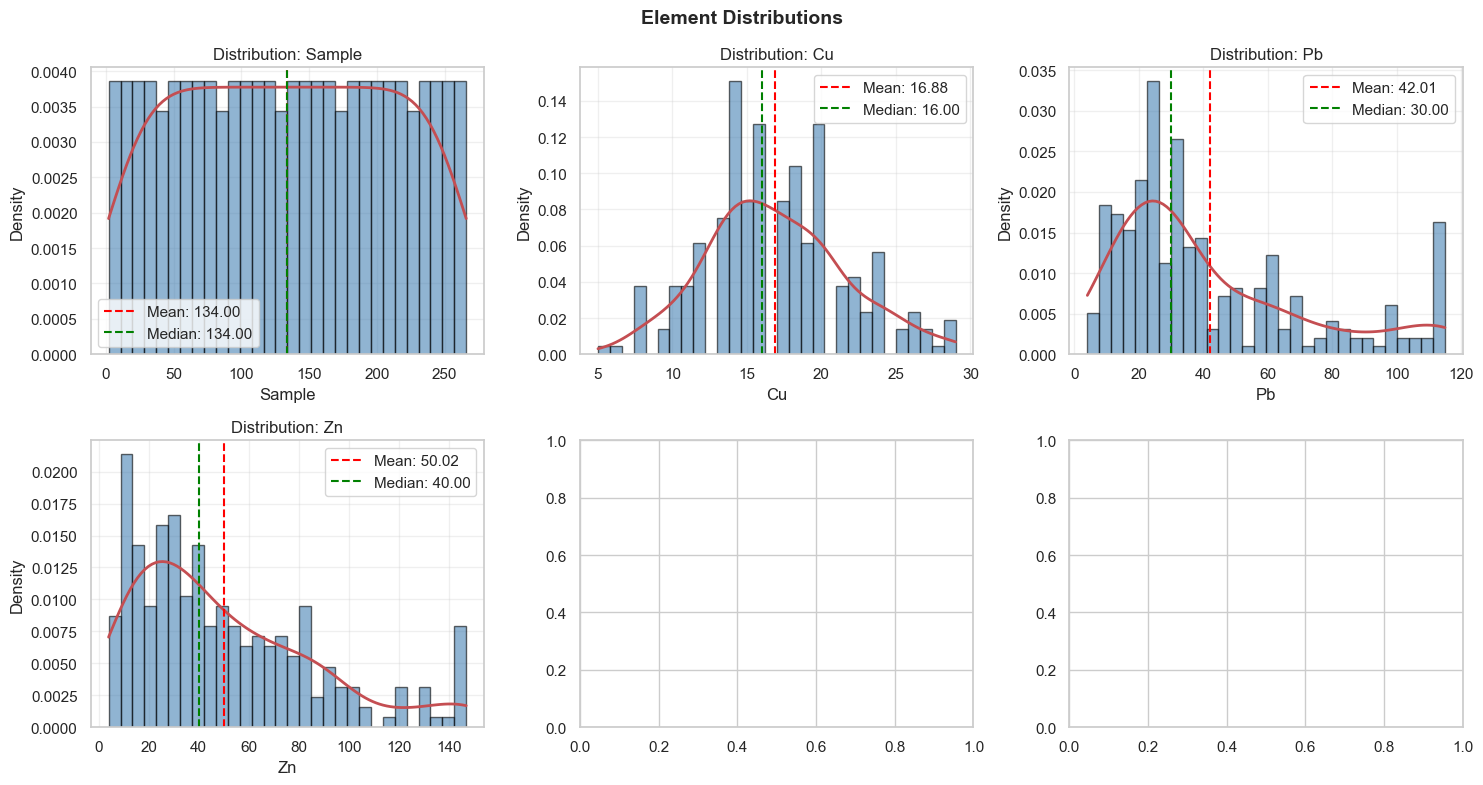

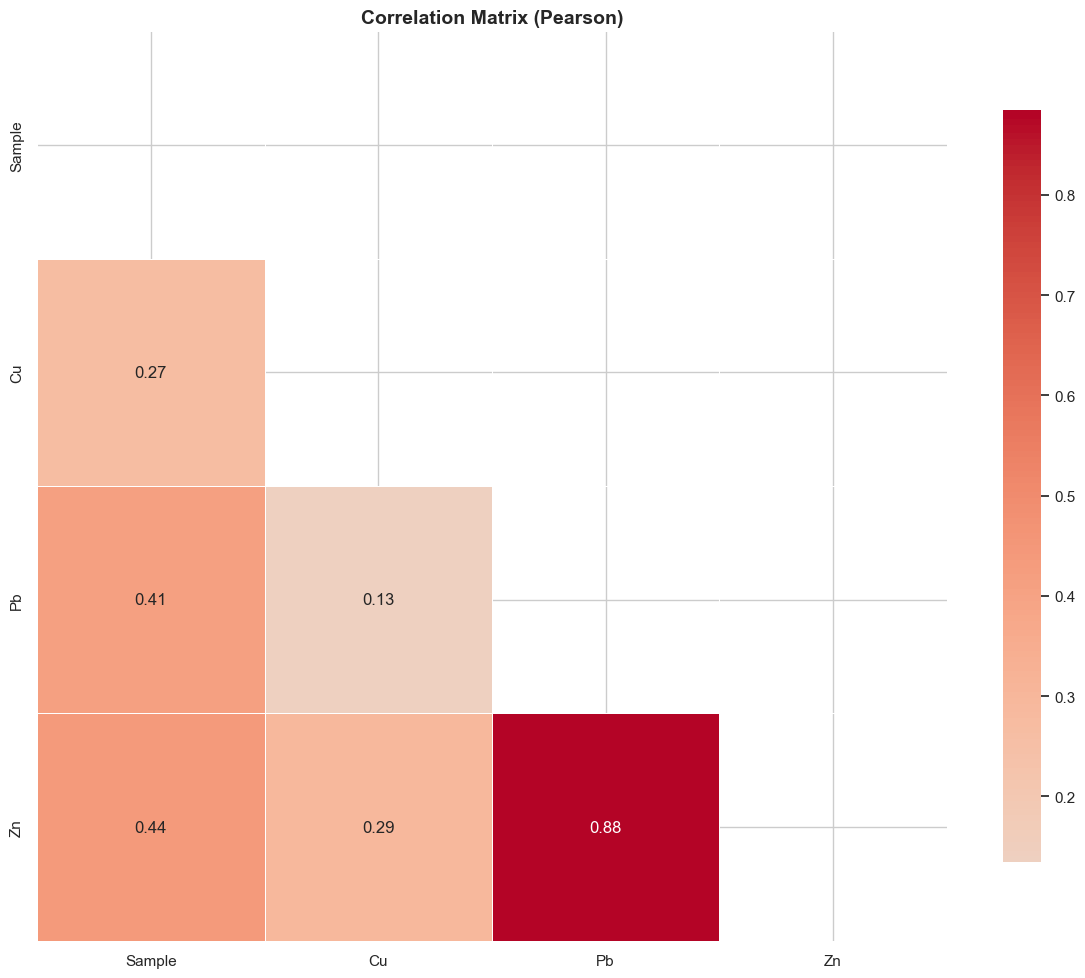

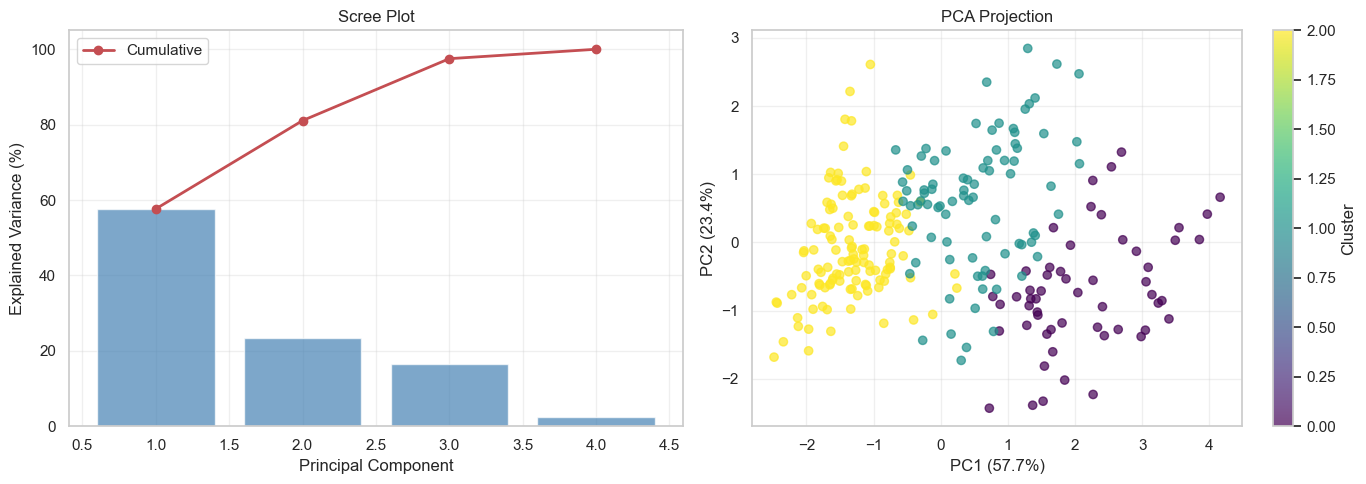

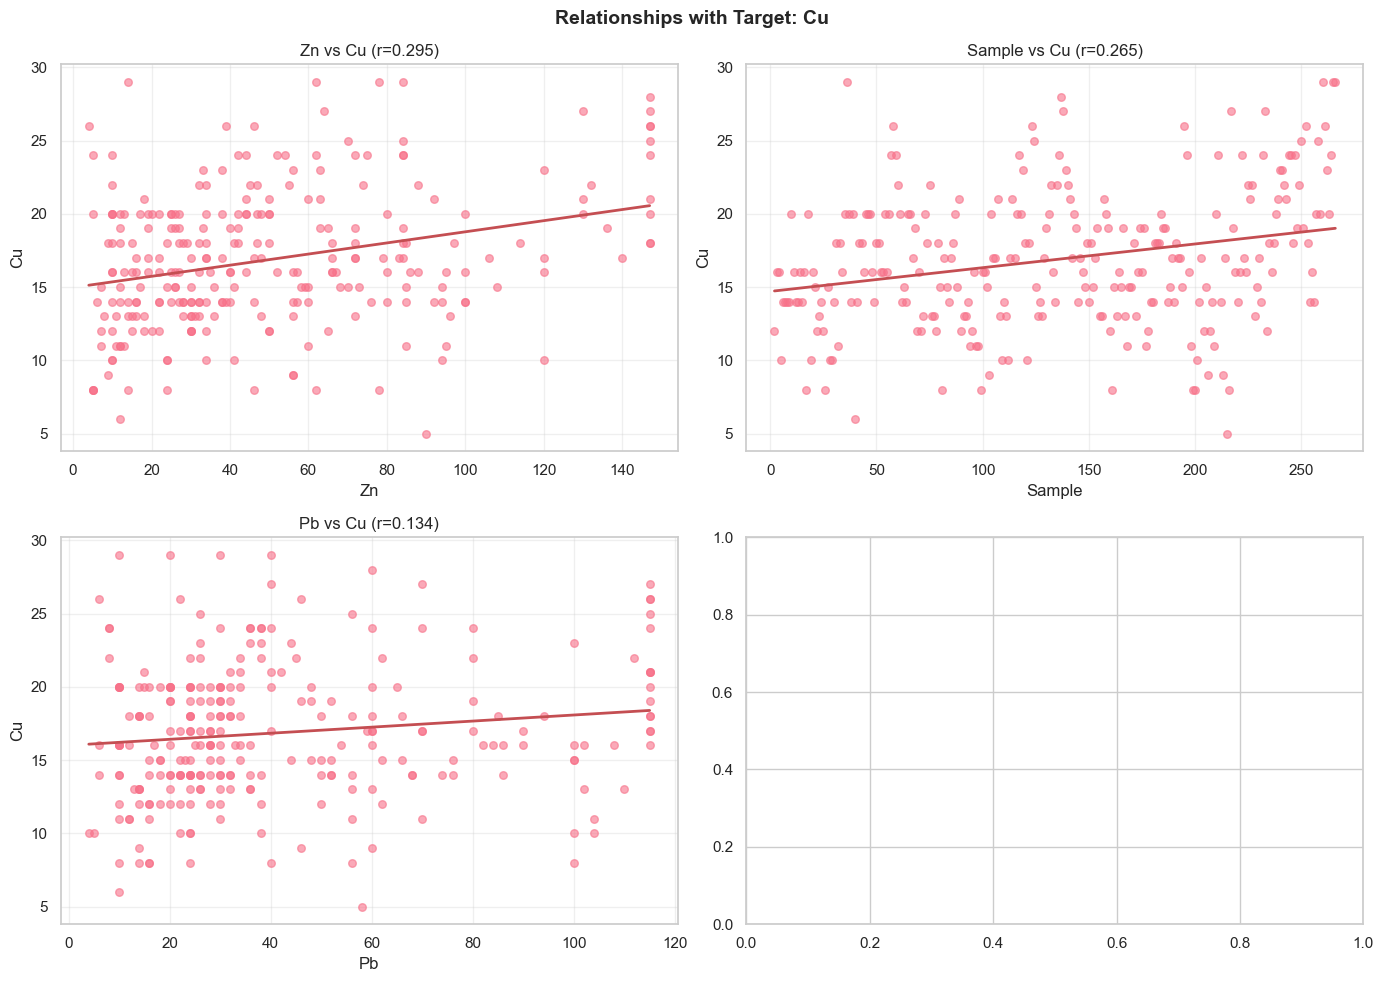

✅ Results exported to geochemical_analysis.xlsx


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr, kendalltau
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import warnings
warnings.filterwarnings('ignore')

# ============================================================
# FIX: Set style with error handling
# ============================================================

try:
    plt.style.use('seaborn-v0-8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        try:
            plt.style.use('whitegrid')
        except OSError:
            print("⚠️ Using default matplotlib style")
            pass

try:
    sns.set_theme(style="whitegrid")
except:
    sns.set_style("whitegrid")

sns.set_palette("husl")

print("✅ Styles loaded successfully!")

class GeochemicalExplorer:
    """
    Complete Exploratory Geochemical Data Analysis
    """
    
    def __init__(self, df, element_columns=None, target=None):
        """
        Initialize the geochemical explorer.
        """
        self.df = df.copy()
        self.original_df = df.copy()
        self.element_columns = element_columns
        self.target = target
        self.results = {}
        
        # Clean data BEFORE identifying numeric columns
        self._clean_data_initial()
        
        # Identify numeric columns
        if self.element_columns is None:
            self.element_columns = self.df.select_dtypes(include=[np.number]).columns.tolist()
        
        # Extract data matrix
        if len(self.element_columns) > 0:
            self.X = self.df[self.element_columns].to_numpy(dtype=float)
        else:
            self.X = np.array([]).reshape(len(self.df), 0)
            print("⚠️ No numeric columns found!")
        
        self.n_samples, self.n_elements = self.X.shape if len(self.X) > 0 else (len(self.df), 0)
        
        print("=" * 70)
        print("🔬 GEOCHEMICAL EXPLORER INITIALIZED")
        print("=" * 70)
        print(f"   Samples: {self.n_samples}")
        print(f"   Elements: {self.n_elements}")
        print(f"   Columns: {self.element_columns}")
        print(f"   Target: {self.target}")
        print("-" * 60)
    
    def _clean_data_initial(self):
        """Initial data cleaning to handle 'ppm' strings."""
        for col in self.df.columns:
            if self.df[col].dtype == 'object':
                mask = self.df[col].astype(str).str.lower() == 'ppm'
                if mask.any():
                    self.df = self.df[~mask]
                    print(f"✅ Removed rows containing 'ppm' in column: {col}")
                    break
        
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        self.df = self.df.reset_index(drop=True)
    
    # ============================================================
    # 1. DATA CLEANING
    # ============================================================
    
    def clean_data(self, remove_first_row=True, handle_outliers=True):
        """
        Clean the geochemical data.
        """
        print("\n🧹 DATA CLEANING")
        print("=" * 60)
        
        if remove_first_row and len(self.df) > 0:
            self.df = self.df.iloc[1:].copy()
            self.df = self.df.reset_index(drop=True)
            print("✅ First row removed")
        
        for col in self.df.columns:
            self.df[col] = pd.to_numeric(self.df[col], errors='coerce')
        
        before = len(self.df)
        self.df = self.df.dropna()
        after = len(self.df)
        print(f"✅ Dropped {before - after} rows with missing values")
        
        if handle_outliers:
            for col in self.element_columns:
                if col in self.df.columns:
                    data = self.df[col]
                    Q1 = data.quantile(0.25)
                    Q3 = data.quantile(0.75)
                    IQR = Q3 - Q1
                    lower = Q1 - 1.5 * IQR
                    upper = Q3 + 1.5 * IQR
                    self.df[col] = data.clip(lower=lower, upper=upper)
            print("✅ Outliers capped")
        
        if len(self.element_columns) > 0:
            self.X = self.df[self.element_columns].to_numpy(dtype=float)
        else:
            self.X = np.array([]).reshape(len(self.df), 0)
        self.n_samples, self.n_elements = self.X.shape if len(self.X) > 0 else (len(self.df), 0)
        
        print(f"✅ Final shape: {self.n_samples} samples, {self.n_elements} elements")
        return self.df
    
    # ============================================================
    # 2. DESCRIPTIVE STATISTICS
    # ============================================================
    
    def descriptive_statistics(self):
        """
        Calculate comprehensive descriptive statistics.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return None
        
        print("\n📊 DESCRIPTIVE STATISTICS")
        print("=" * 60)
        
        stats_df = self.df[self.element_columns].describe().T
        stats_df['variance'] = self.df[self.element_columns].var()
        stats_df['skew'] = self.df[self.element_columns].skew()
        stats_df['kurtosis'] = self.df[self.element_columns].kurtosis()
        stats_df['cv'] = stats_df['std'] / stats_df['mean']
        
        self.results['descriptive_stats'] = stats_df
        print(stats_df.round(4))
        return stats_df
    
    # ============================================================
    # 3. VARIANCE ANALYSIS
    # ============================================================
    
    def variance_analysis(self):
        """
        Analyze variance of each element.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return None
        
        print("\n📈 VARIANCE ANALYSIS")
        print("=" * 60)
        
        variance = self.df[self.element_columns].var()
        std_dev = self.df[self.element_columns].std()
        cv = std_dev / self.df[self.element_columns].mean()
        
        variance_df = pd.DataFrame({
            'Variance': variance,
            'Std_Dev': std_dev,
            'CV': cv
        }).sort_values('Variance', ascending=False)
        
        self.results['variance'] = variance_df
        print(variance_df.round(4))
        
        high_var = variance_df[variance_df['CV'] > 1]
        if len(high_var) > 0:
            print("\n⚠️ High Variability Elements (CV > 1):")
            print(high_var)
        
        return variance_df
    
    # ============================================================
    # 4. COVARIANCE ANALYSIS
    # ============================================================
    
    def covariance_analysis(self):
        """
        Calculate covariance matrix.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for covariance analysis")
            return None
        
        print("\n📊 COVARIANCE MATRIX")
        print("=" * 60)
        
        cov_matrix = self.df[self.element_columns].cov()
        self.results['covariance'] = cov_matrix
        print(cov_matrix.round(4))
        
        strong_cov = []
        for i in range(len(cov_matrix.columns)):
            for j in range(i+1, len(cov_matrix.columns)):
                cov_val = cov_matrix.iloc[i, j]
                if abs(cov_val) > 1:
                    strong_cov.append({
                        'Elements': f"{cov_matrix.columns[i]} - {cov_matrix.columns[j]}",
                        'Covariance': cov_val
                    })
        
        if strong_cov:
            print("\n🔗 Strongest Covariances:")
            strong_df = pd.DataFrame(strong_cov).sort_values('Covariance', ascending=False)
            print(strong_df.head(5))
        
        return cov_matrix
    
    # ============================================================
    # 5. CORRELATION ANALYSIS
    # ============================================================
    
    def correlation_analysis(self):
        """
        Calculate correlations using multiple methods.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation analysis")
            return None, None, None
        
        print("\n🔗 CORRELATION ANALYSIS")
        print("=" * 60)
        
        pearson_corr = self.df[self.element_columns].corr(method='pearson')
        self.results['pearson_correlation'] = pearson_corr
        
        spearman_corr = self.df[self.element_columns].corr(method='spearman')
        self.results['spearman_correlation'] = spearman_corr
        
        kendall_corr = self.df[self.element_columns].corr(method='kendall')
        self.results['kendall_correlation'] = kendall_corr
        
        print("\n📊 Correlation Methods Comparison:")
        print(f"  Pearson:  Linear relationships (parametric)")
        print(f"  Spearman: Monotonic relationships (non-parametric)")
        print(f"  Kendall:  Ordinal relationships (non-parametric)")
        
        strong_pearson = self._find_strong_correlations(pearson_corr, 'Pearson')
        strong_spearman = self._find_strong_correlations(spearman_corr, 'Spearman')
        
        print("\n🔗 Strongest Correlations:")
        print("\nPearson (Linear):")
        for pair in strong_pearson[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        print("\nSpearman (Monotonic):")
        for pair in strong_spearman[:5]:
            print(f"  {pair['Elements']}: {pair['Correlation']:.3f}")
        
        return pearson_corr, spearman_corr, kendall_corr
    
    def _find_strong_correlations(self, corr_matrix, method):
        """Find strong correlations (|r| > 0.7)"""
        strong = []
        for i in range(len(corr_matrix.columns)):
            for j in range(i+1, len(corr_matrix.columns)):
                corr_val = corr_matrix.iloc[i, j]
                if abs(corr_val) > 0.7:
                    strong.append({
                        'Elements': f"{corr_matrix.columns[i]} - {corr_matrix.columns[j]}",
                        'Correlation': corr_val,
                        'Method': method
                    })
        return sorted(strong, key=lambda x: abs(x['Correlation']), reverse=True)
    
    # ============================================================
    # 6. TARGET CORRELATION
    # ============================================================
    
    def target_correlation(self, target=None):
        """
        Analyze correlations with a specific target element.
        """
        if target is None:
            target = self.target
        
        if target is None:
            print("⚠️ No target specified")
            return None
        
        if target not in self.element_columns:
            print(f"⚠️ Target '{target}' not found in data")
            return None
        
        print(f"\n🎯 TARGET CORRELATION: {target}")
        print("=" * 60)
        
        target_correlations = {}
        
        for col in self.element_columns:
            if col == target:
                continue
            pearson_r, pearson_p = pearsonr(self.df[target], self.df[col])
            spearman_r, spearman_p = spearmanr(self.df[target], self.df[col])
            kendall_r, kendall_p = kendalltau(self.df[target], self.df[col])
            
            target_correlations[col] = {
                'Pearson_r': pearson_r,
                'Pearson_p': pearson_p,
                'Spearman_r': spearman_r,
                'Spearman_p': spearman_p,
                'Kendall_r': kendall_r,
                'Kendall_p': kendall_p
            }
        
        corr_df = pd.DataFrame(target_correlations).T
        corr_df = corr_df.sort_values('Pearson_r', ascending=False)
        self.results['target_correlations'] = corr_df
        print(corr_df.round(4))
        
        strong_observers = corr_df[abs(corr_df['Pearson_r']) > 0.5]
        if len(strong_observers) > 0:
            print("\n👁️ Strong Observers (|r| > 0.5):")
            for col, row in strong_observers.iterrows():
                direction = "positive" if row['Pearson_r'] > 0 else "negative"
                print(f"  {col}: {row['Pearson_r']:.3f} ({direction})")
        
        return corr_df
    
    # ============================================================
    # 7. PCA (Principal Component Analysis)
    # ============================================================
    
    def pca_analysis(self, n_components=None):
        """
        Perform PCA for dimensionality reduction.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for PCA")
            return None, None
        
        print("\n🔄 PCA (Principal Component Analysis)")
        print("=" * 60)
        
        # Standardize data
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        if n_components is None:
            n_components = min(self.n_elements, 10)
        
        pca = PCA(n_components=n_components)
        X_pca = pca.fit_transform(X_scaled)
        
        explained_variance = pca.explained_variance_ratio_
        cumulative_variance = np.cumsum(explained_variance)
        
        self.results['pca'] = {
            'components': X_pca,
            'explained_variance': explained_variance,
            'cumulative_variance': cumulative_variance,
            'loadings': pca.components_,
            'n_components': n_components
        }
        
        print(f"\n📊 Explained Variance:")
        for i, (var, cum) in enumerate(zip(explained_variance, cumulative_variance)):
            print(f"  PC{i+1}: {var*100:.1f}% (cumulative: {cum*100:.1f}%)")
        
        n_optimal = np.argmax(cumulative_variance > 0.85) + 1
        print(f"\n🎯 Optimal number of components (85% variance): {n_optimal}")
        
        # 🔧 FIX: Convert numpy array to list for indexing
        print("\n🔍 PCA Component Interpretation (Top 3 components):")
        for i in range(min(3, n_components)):
            loadings = pca.components_[i]
            # Get indices of top 3 features
            top_indices = np.argsort(np.abs(loadings))[::-1][:3]
            # Convert indices to list of column names
            top_features = [self.element_columns[idx] for idx in top_indices]
            print(f"\n  PC{i+1}:")
            for feat in top_features:
                idx = self.element_columns.index(feat)
                print(f"    {feat}: {loadings[idx]:.3f}")
        
        return X_pca, pca
    
    # ============================================================
    # 8. CLUSTERING ANALYSIS
    # ============================================================
    
    def cluster_analysis(self, n_clusters=3):
        """
        Perform K-means clustering on the data.
        """
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for clustering")
            return None, None
        
        print(f"\n🧩 CLUSTERING ANALYSIS (K={n_clusters})")
        print("=" * 60)
        
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(self.X)
        
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        clusters = kmeans.fit_predict(X_scaled)
        self.df['Cluster'] = clusters
        
        cluster_stats = self.df.groupby('Cluster')[self.element_columns].mean()
        print("\n📊 Cluster Characteristics:")
        print(cluster_stats.round(2))
        
        print("\n🔍 Distinct Element Signatures:")
        for cluster in range(n_clusters):
            cluster_data = self.df[self.df['Cluster'] == cluster][self.element_columns]
            cluster_means = cluster_data.mean()
            global_means = self.df[self.element_columns].mean()
            diff = cluster_means - global_means
            
            enriched = diff[diff > 0].sort_values(ascending=False).head(3)
            depleted = diff[diff < 0].sort_values(ascending=True).head(3)
            
            print(f"\n  Cluster {cluster} ({len(cluster_data)} samples):")
            if len(enriched) > 0:
                enriched_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in enriched.index])
                print(f"    Enriched: {enriched_str}")
            if len(depleted) > 0:
                depleted_str = ', '.join([f'{e} ({diff[e]:.2f})' for e in depleted.index])
                print(f"    Depleted: {depleted_str}")
        
        self.results['clusters'] = kmeans
        return clusters, kmeans
    
    # ============================================================
    # 9. VISUALIZATION
    # ============================================================
    
    def plot_distributions(self, columns=None):
        """Plot distributions of elements."""
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to plot")
            return
        
        if columns is None:
            columns = self.element_columns[:6]
        
        n_cols = min(3, len(columns))
        n_rows = (len(columns) + n_cols - 1) // n_cols
        
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
        axes = axes.flatten() if n_rows * n_cols > 1 else [axes]
        
        for i, col in enumerate(columns):
            if i < len(axes):
                ax = axes[i]
                data = self.df[col].dropna()
                
                ax.hist(data, bins=30, density=True, alpha=0.6, color='steelblue', edgecolor='black')
                
                from scipy.stats import gaussian_kde
                if len(data) > 1:
                    kde = gaussian_kde(data)
                    x_range = np.linspace(data.min(), data.max(), 100)
                    ax.plot(x_range, kde(x_range), 'r-', linewidth=2)
                
                ax.axvline(data.mean(), color='red', linestyle='--', label=f'Mean: {data.mean():.2f}')
                ax.axvline(data.median(), color='green', linestyle='--', label=f'Median: {data.median():.2f}')
                ax.set_xlabel(col)
                ax.set_ylabel('Density')
                ax.set_title(f'Distribution: {col}')
                ax.legend()
                ax.grid(True, alpha=0.3)
        
        plt.suptitle('Element Distributions', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_correlation_matrix(self, method='pearson'):
        """Plot correlation matrix heatmap."""
        if len(self.element_columns) < 2:
            print("⚠️ Need at least 2 numeric columns for correlation plot")
            return
        
        corr_matrix = self.df[self.element_columns].corr(method=method)
        
        plt.figure(figsize=(12, 10))
        mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
        sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
                   cmap='coolwarm', center=0, square=True,
                   linewidths=0.5, cbar_kws={"shrink": 0.8})
        plt.title(f'Correlation Matrix ({method.capitalize()})', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    def plot_pca(self):
        """Plot PCA results."""
        if 'pca' not in self.results:
            self.pca_analysis()
        
        if 'pca' not in self.results:
            return
        
        pca_data = self.results['pca']
        X_pca = pca_data['components']
        explained_variance = pca_data['explained_variance']
        
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        ax1 = axes[0]
        components = range(1, len(explained_variance) + 1)
        ax1.bar(components, explained_variance * 100, color='steelblue', alpha=0.7)
        ax1.plot(components, pca_data['cumulative_variance'] * 100, 
                'ro-', linewidth=2, label='Cumulative')
        ax1.set_xlabel('Principal Component')
        ax1.set_ylabel('Explained Variance (%)')
        ax1.set_title('Scree Plot')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        ax2 = axes[1]
        if X_pca.shape[1] >= 2:
            if 'Cluster' in self.df.columns:
                scatter = ax2.scatter(X_pca[:, 0], X_pca[:, 1], 
                                    c=self.df['Cluster'], cmap='viridis', alpha=0.7)
                plt.colorbar(scatter, ax=ax2, label='Cluster')
            else:
                ax2.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=30)
            ax2.set_xlabel(f'PC1 ({explained_variance[0]*100:.1f}%)')
            ax2.set_ylabel(f'PC2 ({explained_variance[1]*100:.1f}%)')
            ax2.set_title('PCA Projection')
            ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def plot_target_relationships(self, target=None):
        """Plot relationships with target element."""
        if target is None:
            target = self.target
        
        if target is None or target not in self.element_columns:
            print("⚠️ No valid target specified")
            return
        
        if 'target_correlations' in self.results:
            corr_df = self.results['target_correlations']
            top_corr = corr_df.nlargest(4, 'Pearson_r').index.tolist()
        else:
            top_corr = [col for col in self.element_columns if col != target][:4]
        
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        axes = axes.flatten()
        
        for i, col in enumerate(top_corr[:4]):
            ax = axes[i]
            ax.scatter(self.df[col], self.df[target], alpha=0.6, s=30)
            
            z = np.polyfit(self.df[col], self.df[target], 1)
            p = np.poly1d(z)
            x_line = np.linspace(self.df[col].min(), self.df[col].max(), 100)
            ax.plot(x_line, p(x_line), 'r-', linewidth=2)
            
            corr = pearsonr(self.df[col], self.df[target])[0]
            ax.set_xlabel(col)
            ax.set_ylabel(target)
            ax.set_title(f'{col} vs {target} (r={corr:.3f})')
            ax.grid(True, alpha=0.3)
        
        plt.suptitle(f'Relationships with Target: {target}', fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
    
    # ============================================================
    # 10. COMPLETE REPORT
    # ============================================================
    
    def full_report(self):
        """
        Generate a complete analysis report.
        """
        if len(self.element_columns) == 0:
            print("⚠️ No numeric columns to analyze")
            return
        
        print("\n" + "█" * 70)
        print("📋 COMPLETE GEOCHEMICAL ANALYSIS REPORT")
        print("█" * 70)
        
        print("\n📁 DATASET OVERVIEW:")
        print(f"  Samples: {self.n_samples}")
        print(f"  Elements: {self.n_elements}")
        print(f"  Columns: {self.element_columns}")
        
        self.descriptive_statistics()
        self.variance_analysis()
        self.correlation_analysis()
        
        if self.target:
            self.target_correlation()
        
        self.pca_analysis()
        self.cluster_analysis()
        
        print("\n" + "█" * 70)
        print("✅ REPORT COMPLETE")
        print("█" * 70)
    
    # ============================================================
    # 11. EXPORT
    # ============================================================
    
    def export_results(self, filename="geochemical_analysis.xlsx"):
        """Export results to Excel."""
        with pd.ExcelWriter(filename) as writer:
            for key, value in self.results.items():
                if isinstance(value, pd.DataFrame):
                    value.to_excel(writer, sheet_name=key[:31])
        
        print(f"✅ Results exported to {filename}")


# ============================================================
# DEMONSTRATION
# ============================================================

if __name__ == "__main__":
    
    print("📊 Loading data...")
    df = pd.read_csv('Brazildata.csv', encoding='cp1252')
    
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print("\nFirst 5 rows:")
    print(df.head())
    
    # Initialize explorer
    explorer = GeochemicalExplorer(df, target='Cu')
    
    # Clean data
    explorer.clean_data(remove_first_row=True, handle_outliers=True)
    
    # Full analysis
    explorer.full_report()
    
    # Visualizations
    explorer.plot_distributions()
    explorer.plot_correlation_matrix('pearson')
    explorer.plot_pca()
    explorer.plot_target_relationships()
    
    # Export results
    explorer.export_results()

In [ ]:
import sys
import os
import pandas as pd
import numpy as np
import re
from pathlib import Path
from scipy import stats
from scipy.optimize import approx_fprime
from scipy.stats import pearsonr, spearmanr, kendalltau, norm, lognorm, skew, kurtosis
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Check if running in Jupyter
try:
    from IPython import get_ipython
    if 'IPKernelApp' in get_ipython().config:
        IN_JUPYTER = True
    else:
        IN_JUPYTER = False
except:
    IN_JUPYTER = False

# Import Qt
try:
    from PyQt5.QtWidgets import *
    from PyQt5.QtCore import *
    from PyQt5.QtGui import *
    QT_VERSION = 5
except ImportError:
    try:
        from PyQt6.QtWidgets import *
        from PyQt6.QtCore import *
        from PyQt6.QtGui import *
        QT_VERSION = 6
    except ImportError:
        print("⚠️ PyQt not installed. Install with: pip install PyQt5")
        QT_VERSION = None

# ============================================================
# PART 1: DATA CLEANING ENGINE
# ============================================================

def clean_any_data(path, sheet_name=None, **kwargs):
    """Universal data cleaner that handles any file format and structure."""
    print(f"\n📁 READING FILE: {os.path.basename(path)}")
    print("=" * 70)
    
    file_ext = Path(path).suffix.lower()
    df = None
    encodings = ['utf-8', 'cp1252', 'latin-1', 'iso-8859-1', 'utf-16', 'cp1250']
    
    if file_ext in ['.xlsx', '.xls', '.xlsm']:
        df = read_excel_file(path, sheet_name)
        if df is None:
            return None
    elif file_ext in ['.csv', '.txt', '.dat', '.tsv']:
        df = read_text_file(path, encodings, **kwargs)
        if df is None or df.empty:
            df = manual_parse_text_file(path)
    else:
        print(f"⚠️ Unknown file type: {file_ext}")
        df = manual_parse_text_file(path)
    
    if df is None or df.empty:
        print("❌ Could not read file")
        return None
    
    print(f"📊 Raw data shape: {df.shape}")
    df = clean_dataframe(df)
    print(f"\n✅ Final shape: {df.shape}")
    return df

def read_excel_file(path, sheet_name):
    try:
        df = pd.read_excel(path, sheet_name=sheet_name, engine='openpyxl')
        print("✅ Read as Excel file (openpyxl)")
        return df
    except:
        try:
            df = pd.read_excel(path, sheet_name=sheet_name, engine='xlrd')
            print("✅ Read as Excel file (xlrd)")
            return df
        except Exception as e:
            print(f"⚠️ Excel read failed: {e}")
            return None

def read_text_file(path, encodings, **kwargs):
    delimiters = [';', ',', '\t', '|', ' ']
    for encoding in encodings:
        for delim in delimiters:
            try:
                df = pd.read_csv(path, sep=delim, encoding=encoding, engine='python', on_bad_lines='skip', **kwargs)
                if df is not None and not df.empty and df.shape[1] > 1:
                    print(f"✅ Read with delimiter: '{delim}' (encoding: {encoding})")
                    return df
            except:
                continue
    return None

def manual_parse_text_file(path):
    try:
        with open(path, 'r', encoding='cp1252') as f:
            lines = f.readlines()
    except:
        try:
            with open(path, 'r', encoding='utf-8') as f:
                lines = f.readlines()
        except:
            return None
    
    lines = [line.strip() for line in lines if line.strip()]
    if not lines:
        return None
    
    first_line = lines[0]
    delimiters = [';', ',', '\t', '|']
    best_delim = None
    max_count = 0
    
    for delim in delimiters:
        count = first_line.count(delim)
        if count > max_count:
            max_count = count
            best_delim = delim
    
    if best_delim:
        data = [line.split(best_delim) for line in lines]
        max_cols = max(len(row) for row in data)
        for row in data:
            if len(row) < max_cols:
                row.extend([''] * (max_cols - len(row)))
        df = pd.DataFrame(data)
        try:
            pd.to_numeric(df.iloc[0, 0])
            return df
        except:
            df.columns = df.iloc[0].tolist()
            df = df.iloc[1:].reset_index(drop=True)
            return df
    return None

def clean_dataframe(df):
    if df is None or df.empty:
        return df
    df = split_single_column(df)
    df = clean_column_names(df)
    df = remove_header_rows(df)
    df = standardize_missing_values(df)
    df = clean_numeric_columns(df)
    df = clean_text_columns(df)
    df = remove_empty(df)
    return df

def split_single_column(df):
    if df is None or df.empty or df.shape[1] != 1:
        return df
    col_name = df.columns[0]
    col_data = df[col_name].astype(str)
    sample = col_data.iloc[0] if len(col_data) > 0 else ''
    delimiters = [';', ',', '\t', '|']
    for delim in delimiters:
        if delim in sample:
            split_data = col_data.str.split(delim, expand=True)
            try:
                pd.to_numeric(split_data.iloc[0, 0])
                split_data.columns = [f'col_{i+1}' for i in range(split_data.shape[1])]
            except:
                headers = split_data.iloc[0].tolist()
                split_data = split_data.iloc[1:].copy()
                headers = [str(h).strip() for h in headers]
                split_data.columns = headers
            return split_data.reset_index(drop=True)
    return df

def clean_column_names(df):
    if df is None or df.empty:
        return df
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.duplicated()]
    df = df.loc[:, ~df.columns.astype(str).str.contains(r',+$', na=False)]
    df.columns = [f'col_{i}' if str(col).strip() == '' or pd.isna(col) else col for i, col in enumerate(df.columns)]
    df.columns = [re.sub(r'[^a-zA-Z0-9_ ]', '_', str(col)).strip('_') for col in df.columns]
    seen = {}
    new_cols = []
    for col in df.columns:
        if col in seen:
            seen[col] += 1
            new_cols.append(f"{col}_{seen[col]}")
        else:
            seen[col] = 0
            new_cols.append(col)
    df.columns = new_cols
    return df

def remove_header_rows(df):
    if df is None or df.empty or len(df) == 0:
        return df
    first_row = df.iloc[0].astype(str)
    header_keywords = ['sample', 'point', 'id', 'name', 'date', 'time', 'value', 'measurement', 'parameter', 'unit', 'ppm']
    header_score = sum(1 for val in first_row if any(keyword in str(val).lower() for keyword in header_keywords))
    if len(first_row) > 0 and header_score / len(first_row) > 0.3:
        df = df.iloc[1:].reset_index(drop=True)
    return df

def standardize_missing_values(df):
    if df is None or df.empty:
        return df
    missing_values = ['', 'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 'na', 'NA', '-', '--', '---', 'n/a', 'N/A', '?']
    df = df.replace(missing_values, np.nan)
    for col in df.columns:
        if col in df.columns:
            df[col] = df[col].astype(str).str.replace(r'^<.*$', 'nan', regex=True)
            df[col] = df[col].astype(str).str.replace(r'^>.*$', 'nan', regex=True)
    return df

def clean_numeric_columns(df):
    if df is None or df.empty:
        return df
    text_cols = ['sample', 'point_id', 'point', 'id', 'name', 'lithology', 'description', 'comment', 'remarks', 'unit', 'method', 'date', 'time']
    def clean_numeric(x):
        if pd.isna(x):
            return np.nan
        x = str(x).strip().replace(',', '.')
        if x.startswith('<') or x.startswith('>'):
            return np.nan
        if x in ['', 'nan', 'NaN', 'NAN', 'null', 'NULL']:
            return np.nan
        x = re.sub(r'[^\d.\-eE+]', '', x)
        try:
            return float(x)
        except:
            return np.nan
    for col in df.columns:
        col_lower = col.lower()
        is_text = any(text in col_lower for text in text_cols)
        if not is_text:
            try:
                df[col] = df[col].map(clean_numeric)
            except:
                try:
                    df[col] = pd.to_numeric(df[col], errors='coerce')
                except:
                    pass
    return df

def clean_text_columns(df):
    if df is None or df.empty:
        return df
    text_cols = df.select_dtypes(include=['object']).columns
    for col in text_cols:
        df[col] = df[col].astype(str).str.strip()
        df[col] = df[col].replace('', np.nan)
        df[col] = df[col].str.replace(r'\s+', ' ', regex=True)
    return df

def remove_empty(df):
    if df is None or df.empty:
        return df
    df = df.dropna(how='all')
    df = df.dropna(axis=1, how='all')
    return df

# ============================================================
# PART 2: PROFESSIONAL EDA ENGINE
# ============================================================

class ProfessionalEDA:
    """
    Professional Exploratory Data Analysis Engine for Geochemical Data
    Features: Variance, Covariance, Correlation (Pearson, Spearman, Kendall),
    PCA, Outlier Detection, PDF Fitting, Jacobian Matrix, and more.
    """
    
    def __init__(self, df, sample_col=None):
        """
        Initialize the EDA engine
        
        Parameters:
        -----------
        df : pandas.DataFrame
            The cleaned dataframe
        sample_col : str, optional
            Column name containing sample IDs
        """
        self.df = df
        self.sample_col = sample_col if sample_col in df.columns else None
        
        # Separate numeric and categorical columns
        self.numeric_df = df.select_dtypes(include=[np.number])
        self.categorical_df = df.select_dtypes(include=['object', 'category'])
        
        # Remove columns with all NaN
        self.numeric_df = self.numeric_df.dropna(axis=1, how='all')
        
        # Results storage
        self.results = {}
        self.cleaned_data = None
        
        print(f"\n{'='*70}")
        print("🔬 PROFESSIONAL EDA ENGINE INITIALIZED")
        print(f"{'='*70}")
        print(f"Total samples: {len(df)}")
        print(f"Numeric variables: {len(self.numeric_df.columns)}")
        print(f"Categorical variables: {len(self.categorical_df.columns)}")
        
        # Run complete analysis
        self.run_complete_analysis()
    
    def run_complete_analysis(self):
        """Execute all statistical analyses"""
        print("\n📊 Running comprehensive EDA...")
        
        # 1. Basic Statistics
        self.calculate_basic_stats()
        
        # 2. Variance Analysis
        self.calculate_variance()
        
        # 3. Covariance Matrix
        self.calculate_covariance()
        
        # 4. Correlation Matrices (Pearson, Spearman, Kendall)
        self.calculate_correlations()
        
        # 5. Outlier Detection
        self.detect_outliers()
        
        # 6. Probability Density Functions
        self.fit_pdfs()
        
        # 7. Jacobian Matrix (sensitivity analysis)
        self.compute_jacobian()
        
        # 8. Principal Component Analysis
        self.perform_pca()
        
        # 9. Eigen decomposition
        self.calculate_eigen()
        
        # 10. Advanced EDA
        self.advanced_eda()
        
        print("✅ Analysis complete!")
    
    def calculate_basic_stats(self):
        """Calculate basic descriptive statistics"""
        self.results['basic_stats'] = {
            'mean': self.numeric_df.mean(),
            'median': self.numeric_df.median(),
            'std': self.numeric_df.std(),
            'min': self.numeric_df.min(),
            'max': self.numeric_df.max(),
            'range': self.numeric_df.max() - self.numeric_df.min(),
            'q25': self.numeric_df.quantile(0.25),
            'q75': self.numeric_df.quantile(0.75),
            'iqr': self.numeric_df.quantile(0.75) - self.numeric_df.quantile(0.25),
            'skewness': self.numeric_df.skew(),
            'kurtosis': self.numeric_df.kurtosis()
        }
        print("✅ Basic statistics calculated")
    
    def calculate_variance(self):
        """Calculate variance and related metrics"""
        self.results['variance'] = {
            'variance': self.numeric_df.var(),
            'std_dev': self.numeric_df.std(),
            'coef_variation': (self.numeric_df.std() / self.numeric_df.mean()) * 100,
            'mean_absolute_dev': self.numeric_df.mad()
        }
        print("✅ Variance analysis complete")
    
    def calculate_covariance(self):
        """Calculate covariance matrix"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['covariance'] = {
                'matrix': clean_data.cov(),
                'trace': np.trace(clean_data.cov().values),
                'determinant': np.linalg.det(clean_data.cov().values) if clean_data.shape[1] > 1 else None
            }
        print("✅ Covariance matrix computed")
    
    def calculate_correlations(self):
        """Calculate multiple correlation matrices"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) > 1:
            self.results['correlations'] = {
                'pearson': clean_data.corr(method='pearson'),
                'spearman': clean_data.corr(method='spearman'),
                'kendall': clean_data.corr(method='kendall')
            }
            
            # Find strongest correlations for each method
            for method in ['pearson', 'spearman', 'kendall']:
                corr_matrix = self.results['correlations'][method]
                if corr_matrix is not None:
                    # Get upper triangle
                    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
                    # Find strongest pairs
                    max_corr = upper.max().max()
                    min_corr = upper.min().min()
                    self.results['correlations'][f'{method}_summary'] = {
                        'max': max_corr,
                        'min': min_corr,
                        'strong_pairs': self._get_strong_correlations(corr_matrix)
                    }
        print("✅ Correlation matrices computed (Pearson, Spearman, Kendall)")
    
    def _get_strong_correlations(self, corr_matrix, threshold=0.7):
        """Extract strong correlation pairs"""
        strong_pairs = []
        for i, col1 in enumerate(corr_matrix.columns):
            for col2 in corr_matrix.columns[i+1:]:
                val = corr_matrix.loc[col1, col2]
                if abs(val) > threshold:
                    strong_pairs.append({
                        'var1': col1,
                        'var2': col2,
                        'correlation': val,
                        'strength': 'strong positive' if val > 0 else 'strong negative'
                    })
        return sorted(strong_pairs, key=lambda x: abs(x['correlation']), reverse=True)
    
    def detect_outliers(self, method='iqr', threshold=1.5):
        """
        Detect outliers using multiple methods
        
        Methods:
        - 'iqr': Interquartile Range method
        - 'zscore': Z-score method
        - 'mad': Median Absolute Deviation method
        """
        self.results['outliers'] = {}
        clean_data = self.numeric_df.dropna()
        
        # IQR Method
        if method == 'iqr' or method == 'all':
            Q1 = clean_data.quantile(0.25)
            Q3 = clean_data.quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - threshold * IQR
            upper_bound = Q3 + threshold * IQR
            
            outliers_iqr = ((clean_data < lower_bound) | (clean_data > upper_bound))
            self.results['outliers']['iqr'] = {
                'count': outliers_iqr.sum(),
                'percentage': (outliers_iqr.sum() / len(clean_data)) * 100,
                'mask': outliers_iqr,
                'lower_bound': lower_bound,
                'upper_bound': upper_bound,
                'variables': outliers_iqr.sum().to_dict()
            }
        
        # Z-Score Method
        if method == 'zscore' or method == 'all':
            z_scores = np.abs(stats.zscore(clean_data))
            outliers_z = z_scores > 3
            self.results['outliers']['zscore'] = {
                'count': outliers_z.sum(),
                'percentage': (outliers_z.sum() / len(clean_data)) * 100,
                'mask': outliers_z,
                'variables': outliers_z.sum().to_dict()
            }
        
        # MAD Method (Median Absolute Deviation)
        if method == 'mad' or method == 'all':
            median = clean_data.median()
            mad = np.abs(clean_data - median).median()
            mad_score = 0.6745 * (clean_data - median) / mad
            outliers_mad = np.abs(mad_score) > 3.5
            self.results['outliers']['mad'] = {
                'count': outliers_mad.sum(),
                'percentage': (outliers_mad.sum() / len(clean_data)) * 100,
                'mask': outliers_mad,
                'variables': outliers_mad.sum().to_dict()
            }
        
        print("✅ Outlier detection complete")
    
    def fit_pdfs(self):
        """
        Fit Probability Density Functions to each numeric variable
        Supports: Normal, Log-normal, Exponential, Weibull, Gamma
        """
        self.results['pdf'] = {}
        
        for col in self.numeric_df.columns:
            data = self.numeric_df[col].dropna()
            if len(data) < 10:
                continue
            
            pdf_results = {'variable': col, 'fits': {}}
            
            # Try different distributions
            distributions = {
                'normal': stats.norm,
                'lognormal': stats.lognorm,
                'exponential': stats.expon,
                'weibull': stats.weibull_min,
                'gamma': stats.gamma,
                'logistic': stats.logistic
            }
            
            # Use Kolmogorov-Smirnov test
            for name, dist in distributions.items():
                try:
                    params = dist.fit(data)
                    ks_stat, p_value = stats.kstest(data, dist.cdf, args=params)
                    pdf_results['fits'][name] = {
                        'params': params,
                        'ks_statistic': ks_stat,
                        'p_value': p_value,
                        'params_dict': self._get_param_names(dist, params)
                    }
                except:
                    continue
            
            # Find best fitting distribution (lowest KS statistic)
            if pdf_results['fits']:
                best_fit = min(pdf_results['fits'].items(), key=lambda x: x[1]['ks_statistic'])
                pdf_results['best_fit'] = best_fit[0]
                pdf_results['best_fit_info'] = best_fit[1]
            
            self.results['pdf'][col] = pdf_results
        
        print("✅ PDF fitting complete")
    
    def _get_param_names(self, dist, params):
        """Get parameter names for distribution"""
        param_names = {
            stats.norm: ['loc', 'scale'],
            stats.lognorm: ['shape', 'loc', 'scale'],
            stats.expon: ['loc', 'scale'],
            stats.weibull_min: ['shape', 'loc', 'scale'],
            stats.gamma: ['shape', 'loc', 'scale'],
            stats.logistic: ['loc', 'scale']
        }
        names = param_names.get(type(dist), [f'param_{i}' for i in range(len(params))])
        return dict(zip(names, params))
    
    def compute_jacobian(self, func=None, epsilon=1e-6):
        """
        Compute the Jacobian matrix for sensitivity analysis
        
        Parameters:
        -----------
        func : callable, optional
            Function that takes a 1D array and returns outputs.
            If None, uses a default function (mean of variables)
        epsilon : float
            Step size for finite differences
        """
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            return
        
        # Default function: calculate mean of each variable
        if func is None:
            def func(x):
                return np.array([np.mean(x) for _ in range(len(x))])
        
        # Compute Jacobian at the mean of each variable
        x0 = clean_data.mean().values
        
        try:
            J = approx_fprime(x0, func, epsilon)
            
            self.results['jacobian'] = {
                'matrix': J,
                'variables': clean_data.columns.tolist(),
                'sensitivity': {
                    col: J[i] for i, col in enumerate(clean_data.columns)
                },
                'magnitudes': np.abs(J).sum(axis=1) if J.ndim > 1 else np.abs(J)
            }
            
            # Identify most sensitive variables
            if J.ndim > 1:
                sensitivities = np.abs(J).sum(axis=0)
            else:
                sensitivities = np.abs(J)
            
            self.results['jacobian']['most_sensitive'] = sorted(
                zip(clean_data.columns, sensitivities),
                key=lambda x: x[1],
                reverse=True
            )[:5]
            
            print("✅ Jacobian matrix computed")
        except Exception as e:
            print(f"⚠️ Jacobian computation failed: {e}")
    
    def perform_pca(self, n_components=None):
        """
        Perform Principal Component Analysis
        
        Parameters:
        -----------
        n_components : int, optional
            Number of components to keep. If None, use all.
        """
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            print("⚠️ Not enough data for PCA")
            return
        
        # Standardize data
        scaler = StandardScaler()
        scaled_data = scaler.fit_transform(clean_data)
        
        # Perform PCA
        if n_components is None:
            n_components = min(clean_data.shape[1], len(clean_data))
        
        pca = SklearnPCA(n_components=n_components)
        pca_scores = pca.fit_transform(scaled_data)
        
        self.results['pca'] = {
            'explained_variance': pca.explained_variance_,
            'explained_variance_ratio': pca.explained_variance_ratio_,
            'cumulative_variance': np.cumsum(pca.explained_variance_ratio_),
            'components': pca.components_,
            'scores': pca_scores,
            'loadings': pd.DataFrame(
                pca.components_.T,
                columns=[f'PC{i+1}' for i in range(pca.n_components_)],
                index=clean_data.columns
            ),
            'n_components': pca.n_components_,
            'n_samples': len(clean_data),
            'scaler': scaler
        }
        
        print(f"✅ PCA complete: {pca.n_components_} components, "
              f"{sum(pca.explained_variance_ratio_)*100:.1f}% variance explained")
    
    def calculate_eigen(self):
        """Calculate eigenvalues and eigenvectors from covariance matrix"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            return
        
        try:
            cov = clean_data.cov().values
            eigenvals, eigenvecs = np.linalg.eig(cov)
            
            # Sort by eigenvalues (largest first)
            idx = np.argsort(eigenvals)[::-1]
            eigenvals = eigenvals[idx]
            eigenvecs = eigenvecs[:, idx]
            
            self.results['eigen'] = {
                'values': eigenvals,
                'vectors': eigenvecs,
                'explained_variance': eigenvals / eigenvals.sum() * 100,
                'variables': clean_data.columns.tolist()
            }
            print("✅ Eigen decomposition complete")
        except Exception as e:
            print(f"⚠️ Eigen decomposition failed: {e}")
    
    def advanced_eda(self):
        """Perform advanced EDA including tests and diagnostics"""
        clean_data = self.numeric_df.dropna()
        if len(clean_data) < 2:
            return
        
        # 1. Normality tests (Shapiro-Wilk)
        self.results['normality_tests'] = {}
        for col in clean_data.columns:
            data = clean_data[col].dropna()
            if len(data) > 3 and len(data) < 5000:  # Shapiro-Wilk limit
                stat, p = stats.shapiro(data)
                self.results['normality_tests'][col] = {
                    'statistic': stat,
                    'p_value': p,
                    'is_normal': p > 0.05,
                    'interpretation': 'Normal' if p > 0.05 else 'Not normal'
                }
        
        # 2. Homogeneity tests (Levene's test)
        if len(clean_data.columns) >= 2:
            groups = [clean_data[col].dropna().values for col in clean_data.columns[:5]]
            if all(len(g) > 1 for g in groups):
                stat, p = stats.levene(*groups)
                self.results['homogeneity'] = {
                    'statistic': stat,
                    'p_value': p,
                    'equal_variances': p > 0.05
                }
        
        # 3. Multivariate normality (Mardia's test - simplified)
        if len(clean_data) > 3:
            try:
                from scipy.spatial.distance import mahalanobis
                cov = clean_data.cov().values
                inv_cov = np.linalg.inv(cov)
                center = clean_data.mean().values
                
                # Calculate Mahalanobis distances
                distances = np.array([mahalanobis(x, center, inv_cov) for x in clean_data.values])
                
                # These should follow chi-square distribution
                chi2 = stats.chi2(df=clean_data.shape[1])
                p_values = 1 - chi2.cdf(distances)
                
                self.results['multivariate'] = {
                    'mahalanobis_distances': distances,
                    'p_values': p_values,
                    'mean_mahalanobis': np.mean(distances),
                    'outliers_mv': np.sum(p_values < 0.001)
                }
            except:
                pass
        
        # 4. Correlation significance tests
        self.results['correlation_tests'] = {}
        corr_matrix = clean_data.corr()
        for i, col1 in enumerate(corr_matrix.columns):
            for col2 in corr_matrix.columns[i+1:]:
                r, p = pearsonr(clean_data[col1], clean_data[col2])
                self.results['correlation_tests'][f'{col1}_vs_{col2}'] = {
                    'correlation': r,
                    'p_value': p,
                    'significant': p < 0.05,
                    'method': 'Pearson'
                }
        
        print("✅ Advanced EDA complete")
    
    def get_cleaned_data(self, outlier_method='iqr'):
        """
        Get cleaned data with outliers removed
        
        Parameters:
        -----------
        outlier_method : str
            Method to use for outlier removal ('iqr', 'zscore', 'mad')
        """
        if outlier_method not in self.results['outliers']:
            print(f"⚠️ {outlier_method} not found, using IQR")
            outlier_method = 'iqr'
        
        outlier_mask = self.results['outliers'][outlier_method]['mask']
        self.cleaned_data = self.df.loc[~outlier_mask.any(axis=1)]
        return self.cleaned_data
    
    def get_report(self, include_all=True):
        """Generate comprehensive EDA report"""
        report = []
        report.append("="*80)
        report.append("🔬 ELEMENTAL SOCIETY ANALYSIS - EDA REPORT")
        report.append("="*80)
        report.append(f"Generated by: Elemental Society Analysis v1.0 (Code: 1010)")
        report.append(f"Dataset: {len(self.df)} samples × {len(self.df.columns)} variables")
        report.append(f"Numeric variables: {len(self.numeric_df.columns)}")
        report.append("")
        
        # 1. Basic Statistics
        report.append("📊 1. BASIC STATISTICS")
        report.append("-"*80)
        stats_df = pd.DataFrame(self.results['basic_stats'])
        report.append(stats_df.round(4).to_string())
        report.append("")
        
        # 2. Variance
        report.append("📈 2. VARIANCE ANALYSIS")
        report.append("-"*80)
        variance_df = pd.DataFrame(self.results['variance'])
        report.append(variance_df.round(4).to_string())
        report.append("")
        
        # 3. Correlations
        report.append("📉 3. STRONG CORRELATIONS")
        report.append("-"*80)
        if 'correlations' in self.results:
            for method in ['pearson', 'spearman', 'kendall']:
                if f'{method}_summary' in self.results['correlations']:
                    report.append(f"\n{method.upper()} Method:")
                    for pair in self.results['correlations'][f'{method}_summary']['strong_pairs'][:5]:
                        report.append(f"  {pair['var1']} ↔ {pair['var2']}: {pair['correlation']:.4f} ({pair['strength']})")
        report.append("")
        
        # 4. Outliers
        report.append("🎯 4. OUTLIER DETECTION")
        report.append("-"*80)
        if 'outliers' in self.results:
            for method, data in self.results['outliers'].items():
                report.append(f"\n{method.upper()} Method:")
                report.append(f"  Total outliers: {data['count']}")
                report.append(f"  Percentage: {data['percentage']:.2f}%")
                report.append("  Variables with outliers:")
                for var, count in sorted(data['variables'].items(), key=lambda x: x[1], reverse=True)[:5]:
                    if count > 0:
                        report.append(f"    {var}: {count}")
        report.append("")
        
        # 5. PDF Fitting
        report.append("📊 5. BEST FIT DISTRIBUTIONS")
        report.append("-"*80)
        if 'pdf' in self.results:
            for col, data in self.results['pdf'].items():
                if 'best_fit' in data:
                    report.append(f"{col}: {data['best_fit']} (KS={data['best_fit_info']['ks_statistic']:.4f}, p={data['best_fit_info']['p_value']:.4f})")
        report.append("")
        
        # 6. PCA
        report.append("📉 6. PRINCIPAL COMPONENT ANALYSIS")
        report.append("-"*80)
        if 'pca' in self.results:
            pca_data = self.results['pca']
            report.append(f"Number of components: {pca_data['n_components']}")
            report.append("Explained variance:")
            for i, (ev_ratio, cum_var) in enumerate(zip(pca_data['explained_variance_ratio'], 
                                                       pca_data['cumulative_variance'])):
                report.append(f"  PC{i+1}: {ev_ratio*100:.1f}% (cumulative: {cum_var*100:.1f}%)")
            report.append("\nTop variable loadings (PC1):")
            loadings = pca_data['loadings']['PC1'].abs().sort_values(ascending=False)[:5]
            for var, loading in loadings.items():
                report.append(f"  {var}: {loading:.4f}")
        report.append("")
        
        # 7. Jacobian (Sensitivity)
        report.append("🔧 7. SENSITIVITY ANALYSIS (JACOBIAN)")
        report.append("-"*80)
        if 'jacobian' in self.results:
            report.append("Most sensitive variables:")
            for var, sens in self.results['jacobian']['most_sensitive']:
                report.append(f"  {var}: {sens:.4f}")
        report.append("")
        
        # 8. Normality Tests
        report.append("📊 8. NORMALITY TESTS")
        report.append("-"*80)
        if 'normality_tests' in self.results:
            for col, data in self.results['normality_tests'].items():
                status = "✅ Normal" if data['is_normal'] else "❌ Not normal"
                report.append(f"  {col}: {status} (p={data['p_value']:.4f})")
        report.append("")
        
        report.append("="*80)
        report.append("📌 EDA Complete - Elemental Society Analysis v1.0")
        report.append("="*80)
        
        return "\n".join(report)

# ============================================================
# PART 3: GUI APPLICATION
# ============================================================

class ElementalSocietyEDA(QMainWindow):
    """Main application window for Elemental Society Analysis"""
    
    def __init__(self):
        super().__init__()
        self.df = None
        self.cleaned_df = None
        self.eda = None
        self.current_file = None
        self.log_messages = []
        self.init_ui()
        
    def init_ui(self):
        """Initialize the user interface"""
        self.setWindowTitle("🧪 Elemental Society Analysis - Professional EDA Suite v2.0")
        self.setGeometry(100, 100, 1400, 900)
        
        # Central widget
        central = QWidget()
        self.setCentralWidget(central)
        main_layout = QVBoxLayout()
        central.setLayout(main_layout)
        
        # Toolbar
        self.create_toolbar()
        
        # Info label
        self.info_label = QLabel("📋 Elemental Society Analysis - Ready for data")
        self.info_label.setStyleSheet("font-size: 14px; font-weight: bold; padding: 15px; background: linear-gradient(to right, #2196F3, #4CAF50); color: white; border-radius: 8px;")